# WT3 against GD1 under six positivity rules

**Question.** Do we reach the same conclusions about AF488+ cells whichever "median + k SD" rule calls them positive?

**The rules.** A cell is AF488+ when its value is above the median + k robust SDs of the junction region's cells, in the same section (the run's way). Two values × three k:

| value | what it is |
|---|---|
| **raw** | the cell's AF488 mean |
| **median filter** | the cell's AF488 mean less the local median (45 µm) — the run's value; k = 7 is the run's rule |

**What is compared, per genotype** (one dot per section):

1. **Crossed cells** — AF488+ cells 2–300 µm past the junction line, in the organoid where AF488 is not at home: the number, and per mm of junction line.
2. **Cells in the junction** — AF488+ cells in the junction region (the counted strip): the number, and per mm of junction line.
3. **Distance of the crossed cells to the organoid edge** — the mean, per section, of the crossed cells' distance to the tissue edge (µm; small = along the surface).
4. **How far the crossed cells went** — the mean distance past the line per section, in µm and divided by the size of the assembloid (a bigger one leaves more room to go), two ways: the **assembloid length** across the line, and the distance from the line to the **centre of the AF488+ cells** at home.
5. **Distance to the edge against distance past the line** — do the cells that travel further stay at the surface? The cells pooled per genotype (binned means), and per section the slope of edge distance on distance past the line.

**Statistics.** Graphs show sections. The test is a mixed model with slide as a random effect (sections on a slide may come from one assembloid) and experiment as a fixed effect: for counts the fold change WT3 / GD1 on log(1 + y), for distances the difference WT3 − GD1 in µm. The last section puts every rule and outcome in one table: same direction, same side of p = 0.05 → same conclusion.

**Pictures.** Sections 10–11 show example cells with which rules call them, and bright-background regions where the raw rules call cells the run's rule does not (likely false positives).

**Data.** The cells-analysis run `cells_analysis\2026-10-28_090440 re-scored` (614 sections), read from the slim cell cache that `03_cells_run.ipynb` writes (`run_analysis_20261028\cache`); if the cache is missing it is built here (a few minutes). Settings, rules and outcomes are in the next cells — change them there.

In [1]:
import ssl

# Some Python installations on Windows cannot read the Windows certificate store.
try:
    ssl.create_default_context()
except ssl.SSLError:  # pragma: no cover - machine-specific
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import json
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.csv as pacsv
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

# ---------------------------------------------------------------- Settings: change these
RUN = Path(r"D:\Slidescanner extracted\cells_analysis\2026-10-28_090440 re-scored")
OUT = Path(r"D:\Slidescanner extracted\run_analysis_20261028")
CACHE = OUT / "cache"                     # shared with 03_cells_run.ipynb
FIGURES = OUT / "figures_genotype"
DESIGN_CSV = Path(r"D:\Slidescanner extracted\Image_File_List.csv")

CHANNEL = "AF488"
GAP_UM = 2.0          # the first µm past the line count as neither side
NEAR_UM = 300.0       # crossed: up to this far past the line
KEEP_UM = 650.0       # cells kept in the cache, from the line
MIN_EDGE = 3          # a section's edge figures need at least this many crossed cells
SAVE_FIGURES = True
# ----------------------------------------------------------------------------------------

FIGURES.mkdir(parents=True, exist_ok=True)
GENOTYPES = ["WT3", "GD1"]
REFERENCE, OTHER = "GD1", "WT3"        # differences and folds are WT3 against GD1

**Style.** Prism-like: thick black axes, every dot, bar and curve edged in black, WT3 blue and GD1 orange throughout. `dots_and_bar` draws one panel; change the look there.

In [2]:
GENOTYPE_COLOURS = {"WT3": "#2a78d6", "GD1": "#eb6834"}
EDGE = dict(edgecolor="black", linewidth=1.1)
mpl.rcParams.update({
    "font.family": "Arial", "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.labelweight": "bold", "axes.linewidth": 1.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.width": 1.8, "ytick.major.width": 1.8, "xtick.major.size": 6, "ytick.major.size": 6,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "svg.fonttype": "none",
})


def save(fig, name):
    if SAVE_FIGURES:
        for ext in ("svg", "png"):
            fig.savefig(FIGURES / f"{name}.{ext}")


def stars(p):
    return "ns" if not np.isfinite(p) or p >= 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"


def dots_and_bar(ax, frame, column, p=None, log=False, seed=0):
    """Bar = mean ± SEM per genotype (black edge), every section as a black-edged dot, bracket with the p."""
    rng = np.random.default_rng(seed)
    top = 0.0
    for k, g in enumerate(GENOTYPES):
        y = pd.to_numeric(frame.loc[frame["Genotype"] == g, column], errors="coerce").dropna().to_numpy()
        if not len(y):
            continue
        top = max(top, y.max())
        ax.bar(k, y.mean(), width=0.62, color=GENOTYPE_COLOURS[g], alpha=0.35, zorder=1, **EDGE)
        ax.errorbar(k, y.mean(), yerr=y.std(ddof=1) / np.sqrt(len(y)), color="black", capsize=7, capthick=1.8,
                    lw=1.8, zorder=4)
        ax.scatter(k + rng.uniform(-0.2, 0.2, len(y)), y, s=12, color=GENOTYPE_COLOURS[g], alpha=0.75, zorder=3,
                   edgecolor="black", linewidth=0.5)
    counts = [int(pd.to_numeric(frame.loc[frame["Genotype"] == g, column], errors="coerce").notna().sum())
              for g in GENOTYPES]
    ax.set_xticks(range(len(GENOTYPES)), [f"{g}\n(n={n})" for g, n in zip(GENOTYPES, counts)])
    ax.set_xlim(-0.6, len(GENOTYPES) - 0.4)
    if log:
        ax.set_yscale("symlog", linthresh=1)
    ax.set_ylim(bottom=0)
    if p is not None:
        y0 = top * (1.5 if log else 1.06)
        ax.plot([0, 0, 1, 1], [y0 * 0.96, y0, y0, y0 * 0.96], color="black", lw=1.5)
        ax.text(0.5, y0 * (1.06 if log else 1.01), f"{stars(p)} (p = {p:.2g})", ha="center", va="bottom", fontsize=9)
        ax.set_ylim(top=y0 * (2.4 if log else 1.14))

## 1. The sections and their cells

From the run: each section's junction length (`cells/<sample>.json`) and its genotype, experiment and slide (file list). From the cache: each cell's position (in the junction region or not, distance to the line, beside it or past its ends, distance to the tissue edge) and its AF488 values.

In [3]:
def read_section(path):
    info = json.loads(path.read_text(encoding="utf-8"))
    return {"name": info["sample"], "length (mm)": info.get("junction_length_um", np.nan) / 1000}


sections = pd.DataFrame([read_section(p) for p in sorted((RUN / "cells").glob("*.json"))])
design = pd.read_csv(DESIGN_CSV)
design["name"] = design["File_Name"].str.replace(".ome.tiff", "", regex=False)
design["slide"] = design["Genotype"] + " e" + design["Experiment"].astype(str) + " s" + design["Slide"].astype(str)
design["Experiment"] = design["Experiment"].astype(str)
sections = sections.merge(design[["name", "Genotype", "Experiment", "slide"]], on="name").set_index("name")

KEEP_COLUMNS = {
    "Label": "label", "Centroid Y (µm)": "y", "Centroid X (µm)": "x", "Nucleus area (µm²)": "area",
    "In region": "region", "Distance to the junction line (µm)": "d", "Beside the junction line": "beside",
    "Distance to the tissue edge (µm)": "edge",
    **{f"{ch} {what}": f"{ch} {what}" for ch in ("AF488", "AF555")
       for what in ("mean", "P95", "ring mean", "ring contrast", "mean (median filter)", "positive")},
}


def slim(name):
    """The kept cells of one section: from the cache (03_cells_run), else read from the run and cached."""
    target = CACHE / f"{name}.parquet"
    if target.exists():
        return pd.read_parquet(target)
    CACHE.mkdir(parents=True, exist_ok=True)
    table = pacsv.read_csv(RUN / "cells" / f"{name}.csv",
                           convert_options=pacsv.ConvertOptions(include_columns=list(KEEP_COLUMNS))).to_pandas()
    table = table.rename(columns=KEEP_COLUMNS)
    table = table[table["region"] | (table["beside"] & (table["d"].abs() <= KEEP_UM))].reset_index(drop=True)
    table.to_parquet(target, index=False)
    return table


cells = {name: slim(name) for name in sections.index}

# Which side of the line is AF488's home: the side with most of the run's AF488+ cells.
# `away` is then the distance into the other organoid (+ = past the line, where crossed cells are).
for name, c in cells.items():
    pos = c[f"{CHANNEL} positive"].to_numpy(bool) & c["beside"].to_numpy(bool)
    sign = -1.0 if pos.sum() >= 5 and np.median(c.loc[pos, "d"]) > 0 else 1.0
    c["away"] = c["d"] * sign
    sections.at[name, "sign"] = sign
print(f"{len(sections)} sections on {sections['slide'].nunique()} slides; "
      + ", ".join(f"{g}: {int((sections['Genotype'] == g).sum())}" for g in GENOTYPES))

614 sections on 36 slides; WT3: 265, GD1: 349


**How big each assembloid is**, to normalise distances by. From every cell of the section (the run's whole-section table, not the cache, which stops at 650 µm), on the axis across the junction line (`away`: − home, + the other organoid):

- **assembloid length** — from the far side of the home organoid to the far side of the other one: the 0.5th to the 99.5th percentile of the cells' distance to the line (cells beside the line);
- **AF488+ centroid to the line** — how far the centre of the AF488+ cells at home (the run's rule) lies from the line: the mean of their distances. The middle of the labelled organoid, roughly.

Worked out once and kept in `OUT/section_scales.csv`; delete it to work them out again.

In [4]:
SCALES_CSV = OUT / "section_scales.csv"
SCALES = {"assembloid length": "assembloid length (µm)", "AF488+ centroid": "AF488+ centroid to the line (µm)"}


def scales_of(name, sign):
    columns = ["Distance to the junction line (µm)", "Beside the junction line", f"{CHANNEL} positive"]
    t = pacsv.read_csv(RUN / "cells" / f"{name}.csv", convert_options=pacsv.ConvertOptions(include_columns=columns)).to_pandas()
    beside = t["Beside the junction line"].to_numpy(bool)
    away = t["Distance to the junction line (µm)"].to_numpy(float)[beside] * sign
    home = away[t[f"{CHANNEL} positive"].to_numpy(bool)[beside] & (away < 0)]
    return {"name": name,
            SCALES["assembloid length"]: np.percentile(away, 99.5) - np.percentile(away, 0.5) if len(away) else np.nan,
            SCALES["AF488+ centroid"]: -home.mean() if len(home) >= 5 else np.nan}


if SCALES_CSV.exists():
    scales = pd.read_csv(SCALES_CSV).set_index("name")
else:
    scales = pd.DataFrame([scales_of(n, sections.at[n, "sign"]) for n in sections.index]).set_index("name")
    scales.to_csv(SCALES_CSV)
for column in SCALES.values():
    sections[column] = scales[column]
display(sections.groupby("Genotype")[list(SCALES.values())].median().round(0).loc[GENOTYPES])

,assembloid length (µm),AF488+ centroid to the line (µm)
Genotype,,
WT3,2032.0,468.0
GD1,1866.0,633.0


## 2. The rules

Each rule's bar is the median + k × the robust SD (1.4826 × MAD) of the **junction region's cells** of the same section, on the raw mean or the median-filtered mean. To add a rule, add a line to `RULES`: `(value column, k)`.

In [5]:
RAW, FILTERED = f"{CHANNEL} mean", f"{CHANNEL} mean (median filter)"
RULES = {
    "raw · median + 3 SD": (RAW, 3.0),
    "raw · median + 5 SD": (RAW, 5.0),
    "raw · median + 7 SD": (RAW, 7.0),
    "median filter · median + 3 SD": (FILTERED, 3.0),
    "median filter · median + 5 SD": (FILTERED, 5.0),
    "median filter · median + 7 SD (run)": (FILTERED, 7.0),
}
RULE_NAMES = list(RULES)


def robust(values):
    v = np.asarray(values, np.float64)
    v = v[np.isfinite(v)]
    if not v.size:
        return np.nan, np.nan
    centre = float(np.median(v))
    return centre, float(np.median(np.abs(v - centre)) * 1.4826)


def positive(c, rule):
    value, k = RULES[rule]
    centre, sd = robust(c.loc[c["region"], value])
    return (c[value] > centre + k * sd).to_numpy()


check = sum(int((positive(cells[n], "median filter · median + 7 SD (run)") != cells[n][f"{CHANNEL} positive"]).sum())
            for n in sections.index)
print(f"the run's rule recomputed: {check} cells called differently from the run (0 expected)")

the run's rule recomputed: 0 cells called differently from the run (0 expected)


## 3. The outcomes, per section and rule

In [6]:
records, crossed_cells = [], []
for name, s in sections.iterrows():
    c = cells[name]
    away, beside, edge = c["away"].to_numpy(), c["beside"].to_numpy(bool), c["edge"].to_numpy(float)
    crossed_zone = beside & (away > GAP_UM) & (away <= NEAR_UM)
    region = c["region"].to_numpy(bool)
    for rule in RULE_NAMES:
        pos = positive(c, rule)
        crossed = pos & crossed_zone
        n_crossed = int(crossed.sum())
        depth, side = away[crossed], edge[crossed]
        slope = np.polyfit(depth, side, 1)[0] if n_crossed >= MIN_EDGE and np.ptp(depth) > 0 else np.nan
        records.append({
            "name": name, "rule": rule, "Genotype": s["Genotype"], "Experiment": s["Experiment"], "slide": s["slide"],
            "crossed cells": n_crossed,
            "crossed per mm": n_crossed / s["length (mm)"],
            "cells in junction": int((pos & region).sum()),
            "in junction per mm": int((pos & region).sum()) / s["length (mm)"],
            "crossed: mean distance to edge (µm)": side.mean() if n_crossed >= MIN_EDGE else np.nan,
            "crossed: mean distance past line (µm)": depth.mean() if n_crossed >= MIN_EDGE else np.nan,
            **{f"crossed: distance past line ÷ {scale}": depth.mean() / s[column] if n_crossed >= MIN_EDGE else np.nan
               for scale, column in SCALES.items()},
            "crossed: edge vs line slope": slope,
        })
        crossed_cells.append(pd.DataFrame({"rule": rule, "Genotype": s["Genotype"], "name": name,
                                           "past the line (µm)": depth, "to the edge (µm)": side,
                                           **{f"past the line ÷ {scale}": depth / s[column]
                                              for scale, column in SCALES.items()}}))
obs = pd.DataFrame(records)
crossed_cells = pd.concat(crossed_cells, ignore_index=True)
print(f"{len(obs)} rows: {len(sections)} sections × {len(RULE_NAMES)} rules")
display(obs.groupby(["rule", "Genotype"])[["crossed cells", "crossed per mm", "cells in junction", "in junction per mm",
                                            "crossed: mean distance to edge (µm)", "crossed: mean distance past line (µm)",
                                            *[f"crossed: distance past line ÷ {scale}" for scale in SCALES],
                                            "crossed: edge vs line slope"]]
        .median().round(2).loc[RULE_NAMES])

3684 rows: 614 sections × 6 rules


crossed cells  crossed per mm  cells in junction  in junction per mm  crossed: mean distance to edge (µm)  crossed: mean distance past line (µm)  \
rule                                Genotype                                                                                                                                                     
raw · median + 3 SD                 GD1                87.0           77.60               96.0               85.80                               331.01                                 142.62   
                                    WT3               131.0          142.21              165.0              168.15                               224.24                                 123.36   
raw · median + 5 SD                 GD1                 7.0            5.94                7.0                6.42                               318.83                                 114.12   
                                    WT3                24.0           26.06               28.0               34.58                               187.25                                  92.81   
raw · median + 7 SD                 GD1                 1.0            1.04                1.0                1.18                               264.98                                  85.45   
                                    WT3                 7.0            7.46               11.0                9.80                               169.69                                  78.41   
median filter · median + 3 SD       GD1               101.0           86.33              104.0               89.72                               317.61                                 137.07   
                                    WT3               113.0          115.09              134.0              137.12                               244.00                                 121.97   
median filter · median + 5 SD       GD1                21.0           19.36               22.0               20.12                               309.25                                 120.40   
                                    WT3                41.0           40.63               46.0               48.03                               220.11                                 104.76   
median filter · median + 7 SD (run) GD1                 8.0            7.51                9.0                8.28                               293.71                                 105.50   
                                    WT3                21.0           24.21               26.0               26.98                               207.97                                  91.96   

                                              crossed: distance past line ÷ assembloid length  crossed: distance past line ÷ AF488+ centroid  crossed: edge vs line slope  
rule                                Genotype                                                                                                                               
raw · median + 3 SD                 GD1                                                  0.08                                           0.22                        -0.06  
                                    WT3                                                  0.06                                           0.26                         0.22  
raw · median + 5 SD                 GD1                                                  0.06                                           0.18                        -0.10  
                                    WT3                                                  0.05                                           0.22                         0.19  
raw · median + 7 SD                 GD1                                                  0.05                                           0.14                        -0.06  
                                    WT3                                                  0.04                                

## 4. The mixed model

For every rule and outcome: counts on log(1 + y) → **fold WT3 / GD1**; distances and the slope as they are → **difference WT3 − GD1**. Slide random, experiment fixed.

In [7]:
OUTCOMES = {  # outcome → ("fold" for counts on log(1 + y), "difference" for µm or slope), axis label
    "crossed cells": ("fold", "AF488+ cells that crossed\n(per section)"),
    "crossed per mm": ("fold", "AF488+ cells that crossed\n(per mm of junction)"),
    "cells in junction": ("fold", "AF488+ cells in the junction region\n(per section)"),
    "in junction per mm": ("fold", "AF488+ cells in the junction region\n(per mm of junction)"),
    "crossed: mean distance to edge (µm)": ("difference", "crossed cells: mean distance\nto the organoid edge (µm)"),
    "crossed: mean distance past line (µm)": ("difference", "crossed cells: mean distance\npast the line (µm)"),
    **{f"crossed: distance past line ÷ {scale}": ("difference", f"crossed cells: mean distance past\nthe line ÷ {scale}")
       for scale in SCALES},
    "crossed: edge vs line slope": ("difference", "crossed cells: µm further from the edge\nper µm further past the line"),
}
TERM = f"C(Genotype, Treatment('{REFERENCE}'))[T.{OTHER}]"


def mixed(frame, column, kind):
    d = frame[["Genotype", "Experiment", "slide"]].copy()
    y = pd.to_numeric(frame[column], errors="coerce")
    d["y"] = np.log1p(y) if kind == "fold" else y
    d = d.dropna()
    fit = smf.mixedlm(f"y ~ C(Genotype, Treatment('{REFERENCE}')) + C(Experiment)", d, groups=d["slide"]).fit(reml=True)
    est, (lo, hi) = fit.params[TERM], fit.conf_int().loc[TERM]
    if kind == "fold":
        est, lo, hi = np.exp(est), np.exp(lo), np.exp(hi)
    return {"effect": est, "CI low": lo, "CI high": hi, "p": fit.pvalues[TERM], "sections": len(d)}


effects = pd.DataFrame([{"rule": rule, "outcome": outcome, "kind": kind,
                         **mixed(obs[obs["rule"] == rule], outcome, kind)}
                        for rule in RULE_NAMES for outcome, (kind, _label) in OUTCOMES.items()])
display(effects.set_index(["outcome", "rule"]).round(3))

,,kind,effect,CI low,CI high,p,sections
outcome,rule,,,,,,
crossed cells,raw · median + 3 SD,fold,1.615,0.920,2.834,0.095,614
crossed per mm,raw · median + 3 SD,fold,1.839,1.124,3.008,0.015,614
cells in junction,raw · median + 3 SD,fold,1.763,1.008,3.083,0.047,614
in junction per mm,raw · median + 3 SD,fold,1.999,1.219,3.278,0.006,614
crossed: mean distance to edge (µm),raw · median + 3 SD,difference,-81.555,-128.706,-34.404,0.001,600
crossed: mean distance past line (µm),raw · median + 3 SD,difference,-13.881,-31.783,4.022,0.129,600
crossed: distance past line ÷ assembloid length,raw · median + 3 SD,difference,-0.011,-0.022,-0.000,0.047,600
crossed: distance past line ÷ AF488+ centroid,raw · median + 3 SD,difference,0.063,0.012,0.114,0.016,600
crossed: edge vs line slope,raw · median + 3 SD,difference,0.285,0.121,0.449,0.001,600


## 5. Crossed cells, by genotype

Top row: the number of AF488+ cells past the line per section; bottom row: the same per mm of junction line. One column per rule; one dot per section; bar = mean ± SEM; p from the mixed model.

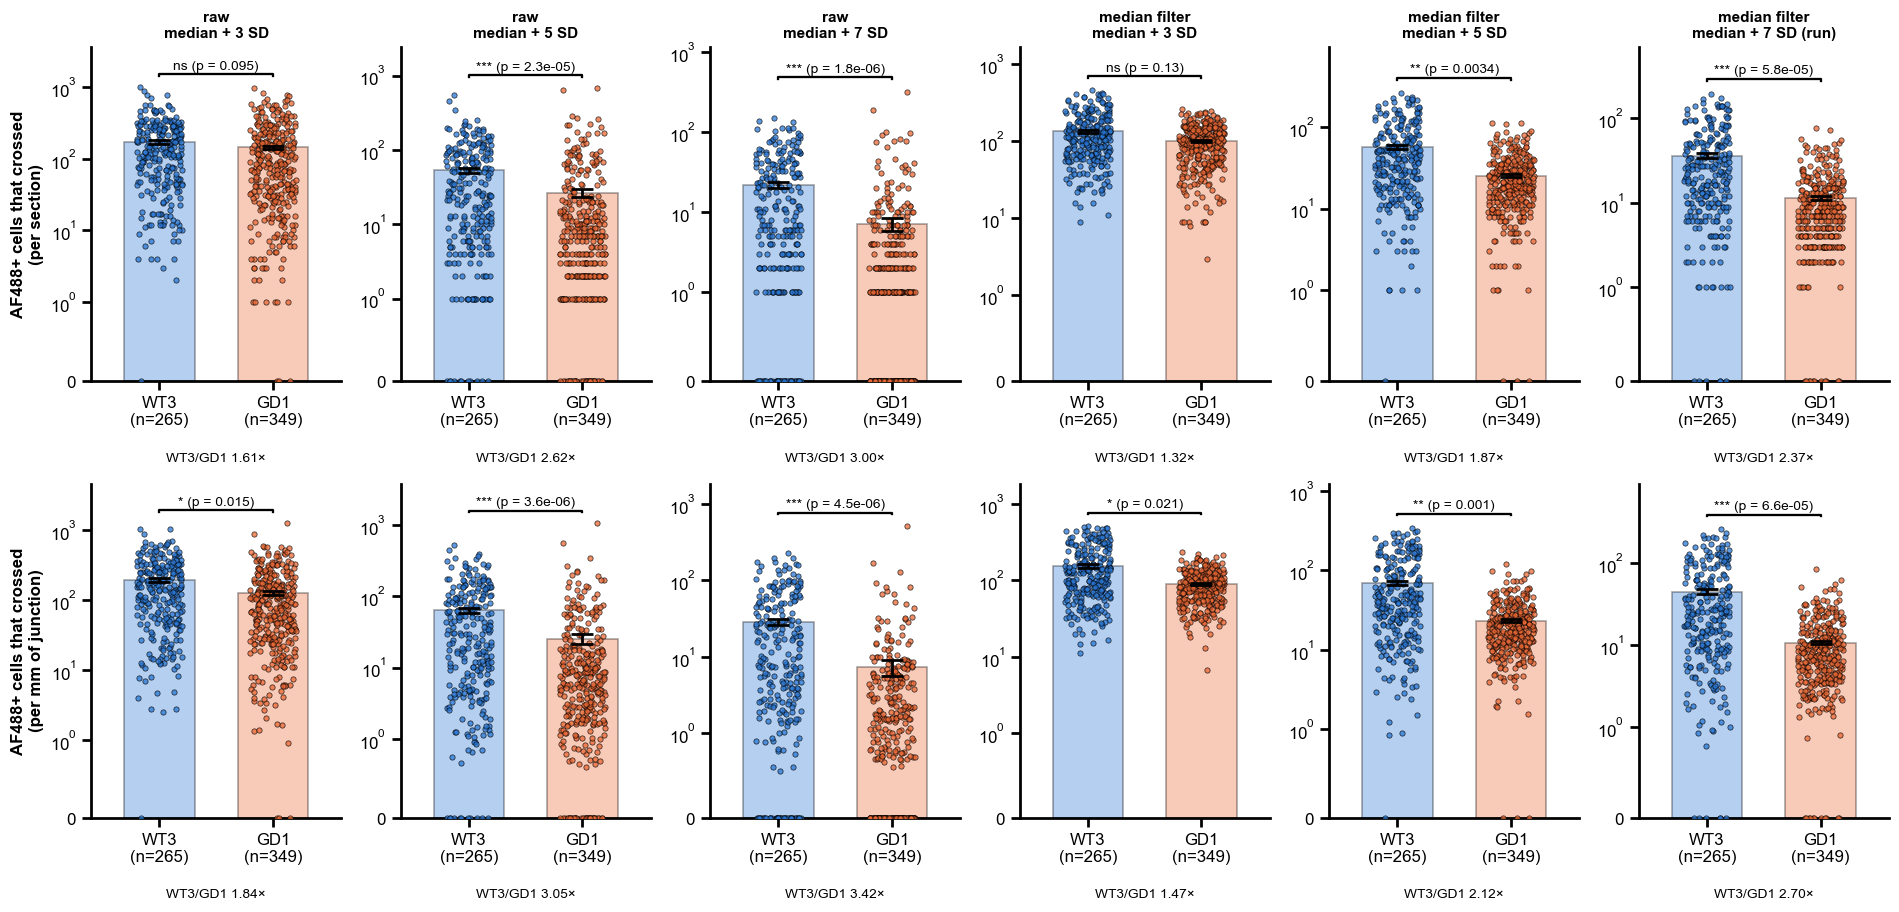

In [8]:
def grid(outcomes, name, log=True):
    fig, axes = plt.subplots(len(outcomes), len(RULE_NAMES), figsize=(2.9 * len(RULE_NAMES), 4.2 * len(outcomes)),
                             squeeze=False)
    for i, outcome in enumerate(outcomes):
        for j, rule in enumerate(RULE_NAMES):
            ax = axes[i, j]
            e = effects[(effects["rule"] == rule) & (effects["outcome"] == outcome)].iloc[0]
            dots_and_bar(ax, obs[obs["rule"] == rule], outcome, p=e["p"], log=log)
            if i == 0:
                ax.set_title(rule.replace(" · ", "\n"), fontsize=10)
            if j == 0:
                ax.set_ylabel(OUTCOMES[outcome][1])
            if e["kind"] == "fold":
                label = f"WT3/GD1 {e['effect']:.2f}×"
            elif "µm" in outcome:
                label = f"WT3 − GD1 {e['effect']:+.1f} µm"
            else:
                label = f"WT3 − GD1 {e['effect']:+.3f}"
            ax.text(0.5, -0.24, label, transform=ax.transAxes, ha="center", fontsize=9)
    fig.tight_layout()
    save(fig, name)
    plt.show()


grid(["crossed cells", "crossed per mm"], "crossed_cells")

## 6. AF488+ cells in the junction region, by genotype

The same for the cells in the junction region (the counted strip on the far side of the line): the number per section, and per mm of junction line.

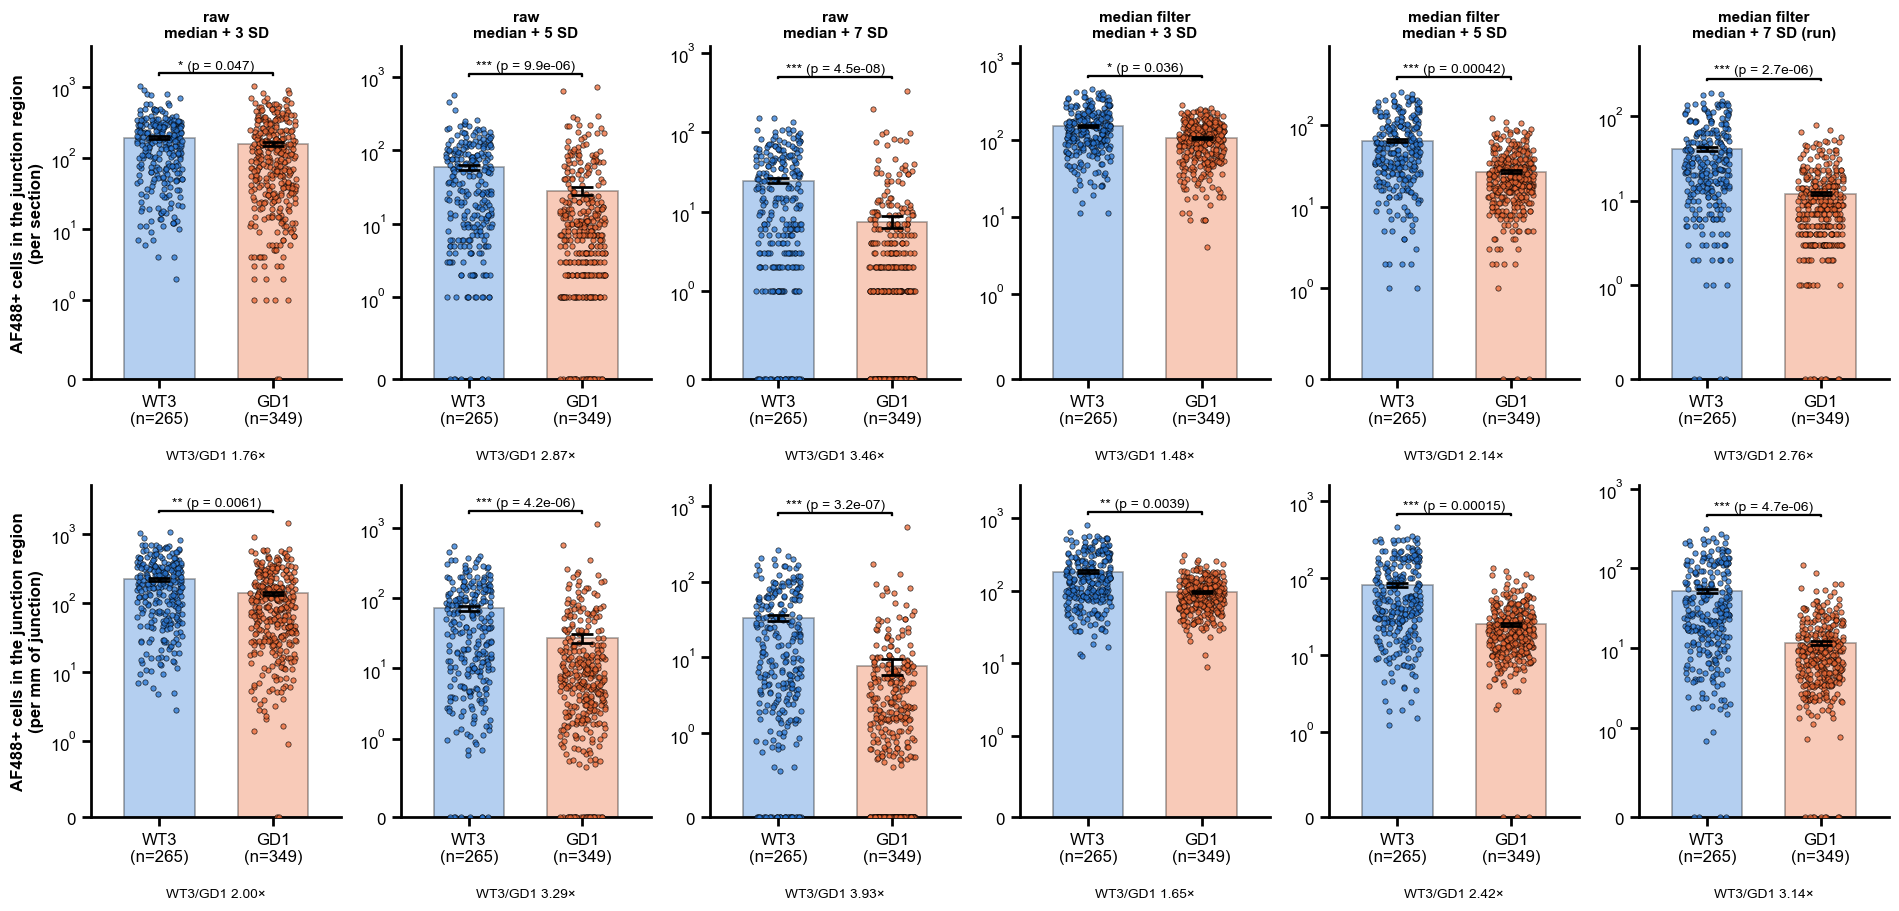

In [9]:
grid(["cells in junction", "in junction per mm"], "junction_cells")

## 7. How far the crossed cells are from the organoid edge

Per section, the mean distance to the tissue edge of its crossed AF488+ cells (sections with at least `MIN_EDGE` of them). Smaller = nearer the surface.

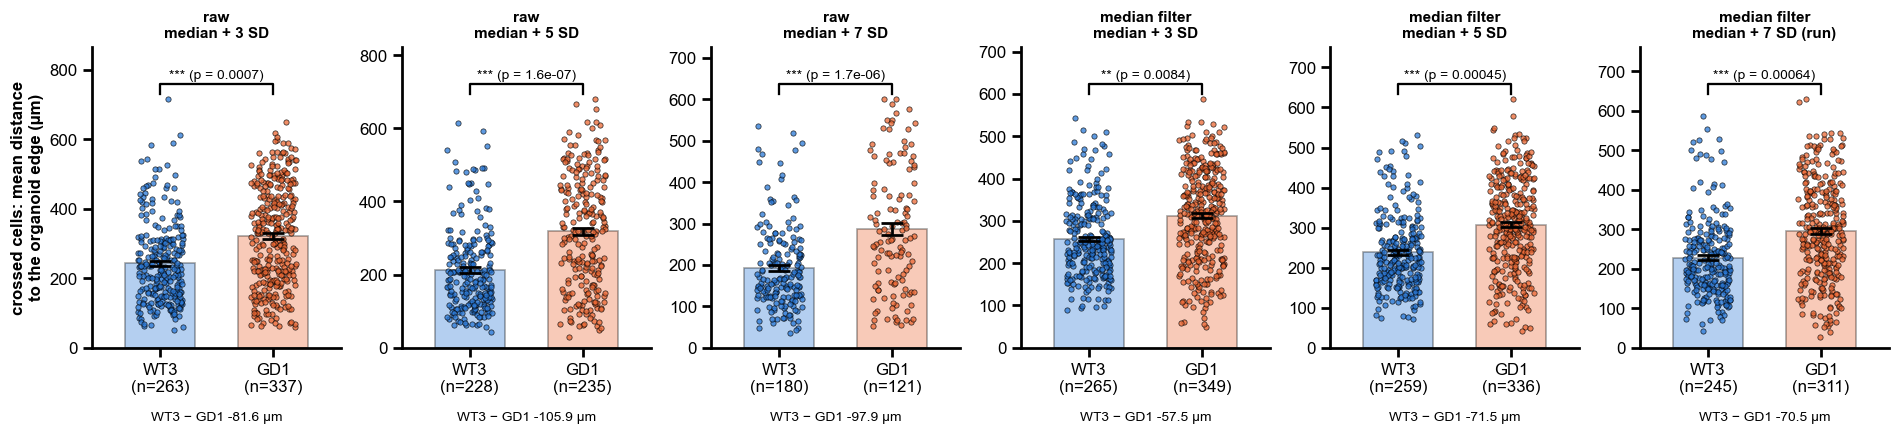

In [10]:
grid(["crossed: mean distance to edge (µm)"], "crossed_edge_distance", log=False)

## 7b. How far the crossed cells went past the line

Per section, the mean distance past the junction line of its crossed AF488+ cells (sections with at least `MIN_EDGE` of them): first row in µm, then divided by the assembloid length (0.1 = a tenth of the assembloid), then by the distance from the line to the AF488+ centroid (0.5 = half as far past the line as the labelled cells' centre is behind it). Crossed cells are only counted up to 300 µm past the line (`NEAR_UM`), so this is how deep they went within that strip.

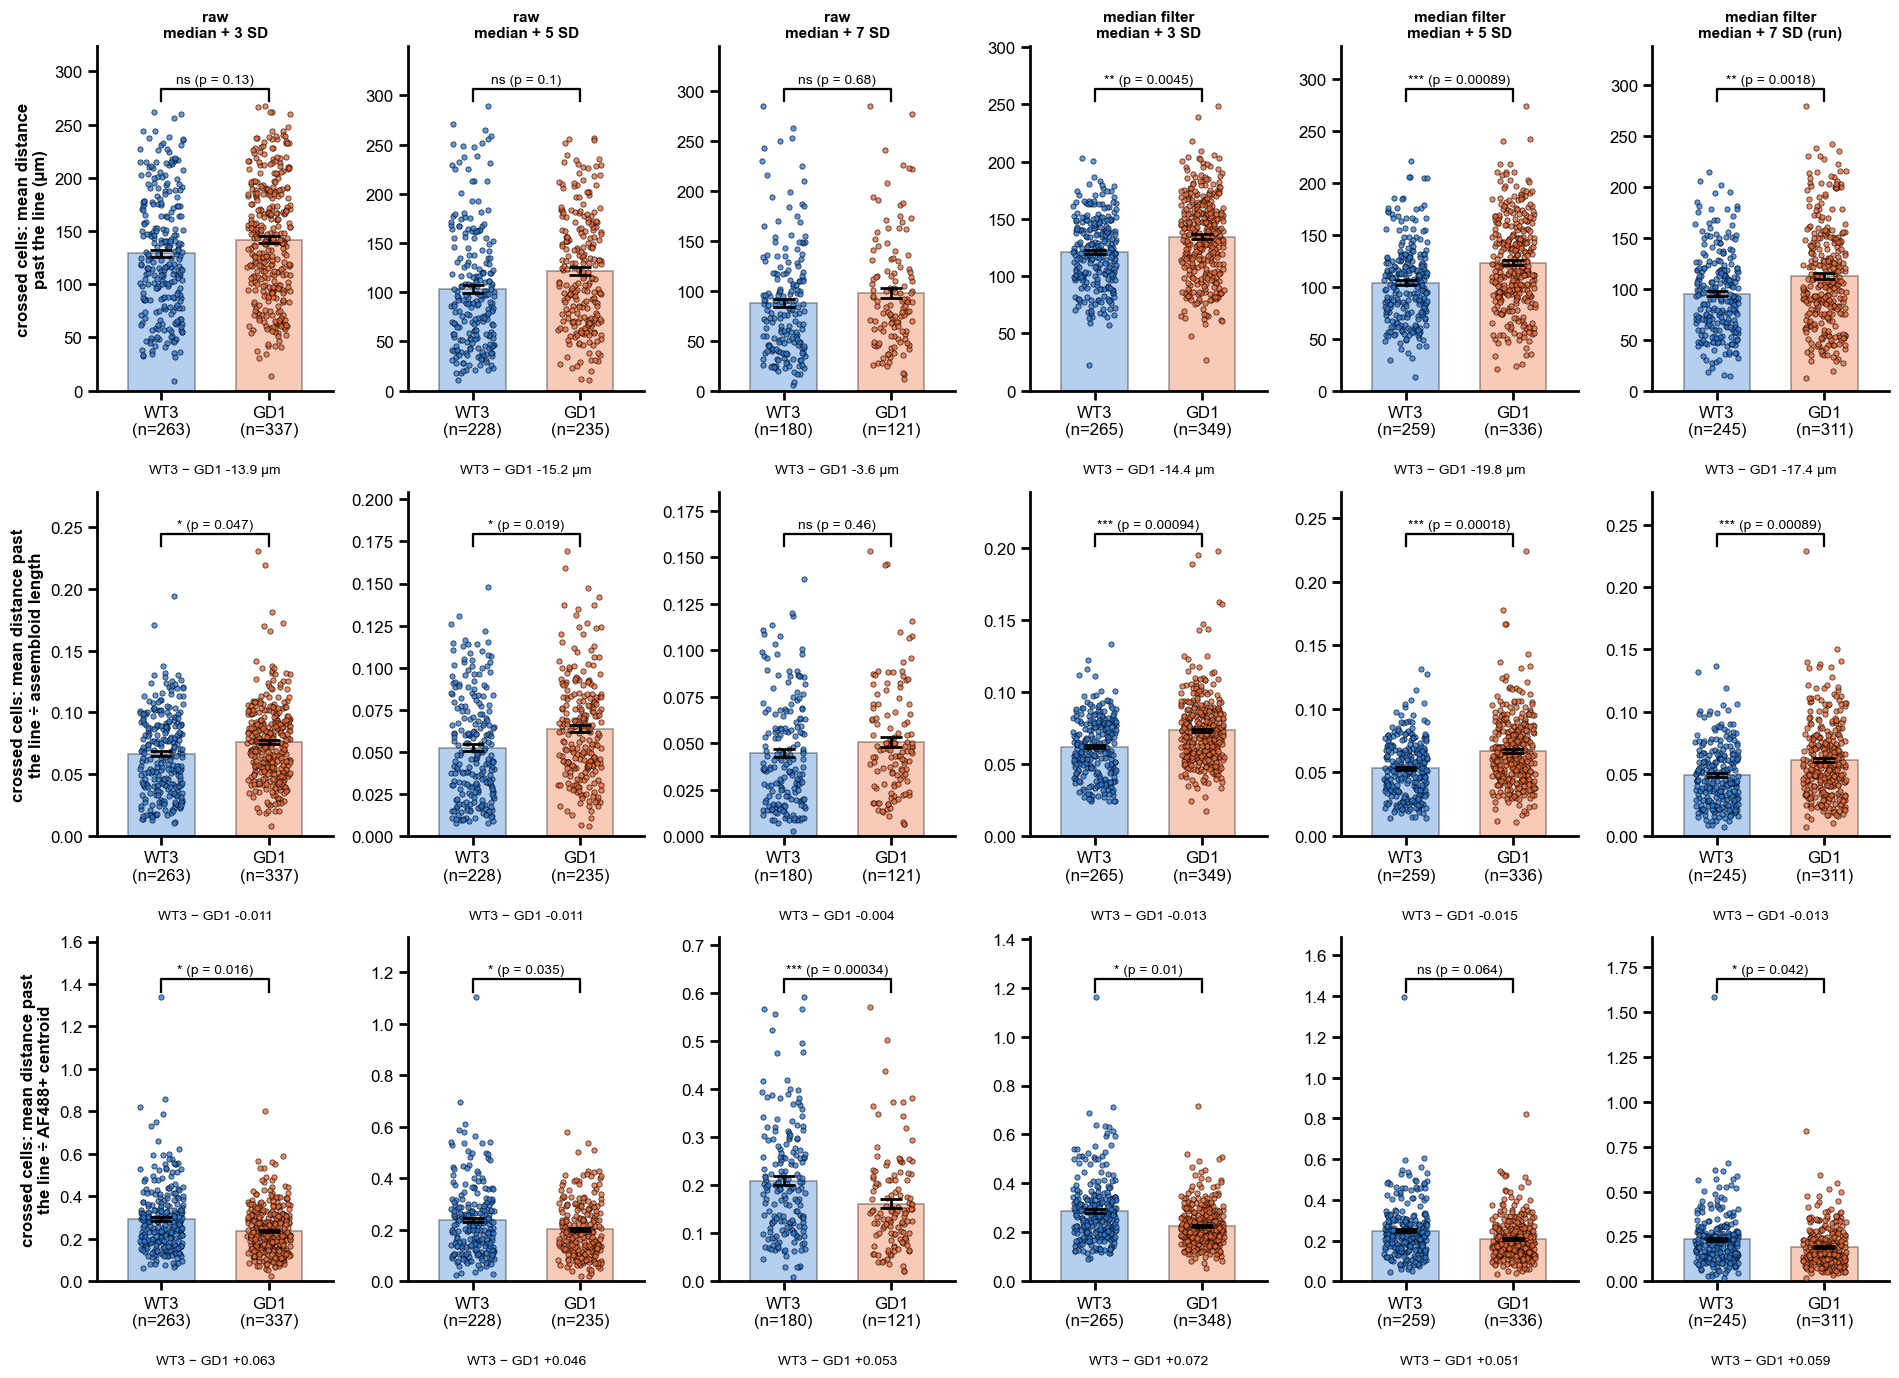

In [11]:
grid(["crossed: mean distance past line (µm)", *[f"crossed: distance past line ÷ {scale}" for scale in SCALES]],
     "crossed_distance_past_line", log=False)

## 8. Distance to the edge against distance past the line

Do the cells that went further stay on the surface? Top: every crossed AF488+ cell pooled per genotype, binned by distance past the line (25 µm bins): mean distance to the edge ± SEM. A rising curve: the further a cell went, the deeper into the tissue it is; a flat one: depth past the line does not matter. Bottom: per section (at least `MIN_EDGE` crossed cells), the slope of the same — µm further from the edge per µm further past the line (0 = flat) — with the mixed model's p. The y axis is cut at the 2nd and 98th percentiles; a few extreme slopes (sections with 3–4 crossed cells) are off the panel.

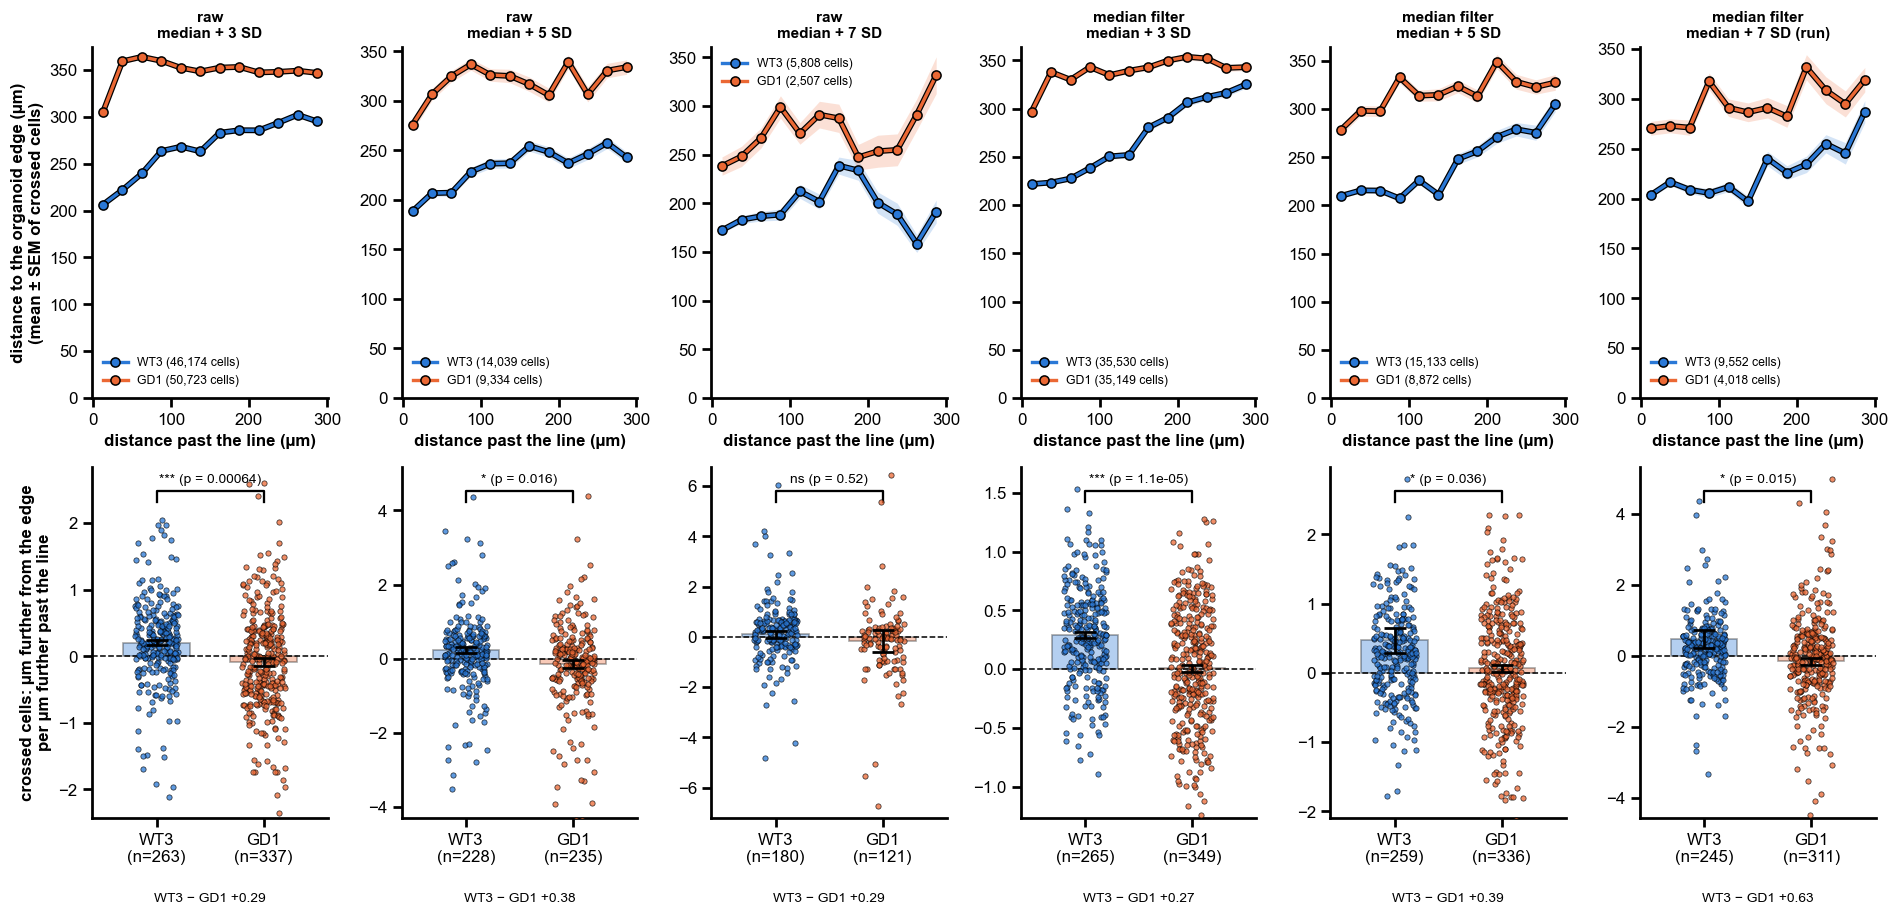

In [12]:
BINS = np.arange(0, NEAR_UM + 1, 25)
centres = (BINS[:-1] + BINS[1:]) / 2
fig, axes = plt.subplots(2, len(RULE_NAMES), figsize=(2.9 * len(RULE_NAMES), 8.4), squeeze=False)
for j, rule in enumerate(RULE_NAMES):
    ax = axes[0, j]
    part = crossed_cells[crossed_cells["rule"] == rule]
    for g in GENOTYPES:
        cg = part[part["Genotype"] == g]
        b = np.digitize(cg["past the line (µm)"], BINS) - 1
        stat = cg.groupby(b)["to the edge (µm)"].agg(["mean", "sem", "size"]).reindex(range(len(centres)))
        stat = stat[stat["size"] >= 10]
        x = centres[stat.index]
        ax.fill_between(x, stat["mean"] - stat["sem"], stat["mean"] + stat["sem"], color=GENOTYPE_COLOURS[g],
                        alpha=0.2, lw=0)
        ax.plot(x, stat["mean"], color="black", lw=3.8, zorder=2)
        ax.plot(x, stat["mean"], color=GENOTYPE_COLOURS[g], lw=2.2, marker="o", ms=6, mec="black", mew=1,
                zorder=3, label=f"{g} ({len(cg):,} cells)")
    ax.set_title(rule.replace(" · ", "\n"), fontsize=10)
    ax.set_xlabel("distance past the line (µm)")
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=8)
    if j == 0:
        ax.set_ylabel("distance to the organoid edge (µm)\n(mean ± SEM of crossed cells)")
    e = effects[(effects["rule"] == rule) & (effects["outcome"] == "crossed: edge vs line slope")].iloc[0]
    ax = axes[1, j]
    dots_and_bar(ax, obs[obs["rule"] == rule], "crossed: edge vs line slope")
    ax.axhline(0, color="black", lw=1, ls="--")
    lo, hi = obs.loc[obs["rule"] == rule, "crossed: edge vs line slope"].quantile([0.02, 0.98])
    ax.set_ylim(lo - 0.3 * abs(lo), hi + 0.6 * abs(hi))       # the few extreme slopes are off the panel
    ax.plot([0, 0, 1, 1], [0.9, 0.93, 0.93, 0.9], color="black", lw=1.5, transform=ax.get_xaxis_transform())
    ax.text(0.5, 0.945, f"{stars(e['p'])} (p = {e['p']:.2g})", ha="center", va="bottom", fontsize=9,
            transform=ax.get_xaxis_transform())
    ax.text(0.5, -0.24, f"WT3 − GD1 {e['effect']:+.2f}", transform=ax.transAxes, ha="center", fontsize=9)
    if j == 0:
        axes[1, j].set_ylabel(OUTCOMES["crossed: edge vs line slope"][1])
fig.tight_layout()
save(fig, "edge_vs_line")
plt.show()

**The same, distance past the line normalised.** Each crossed cell's distance past the line over its section's assembloid length (top) and over its AF488+ centroid's distance to the line (bottom), in 15 bins up to the 99th percentile; mean distance to the edge ± SEM; bins with fewer than 10 cells left out.

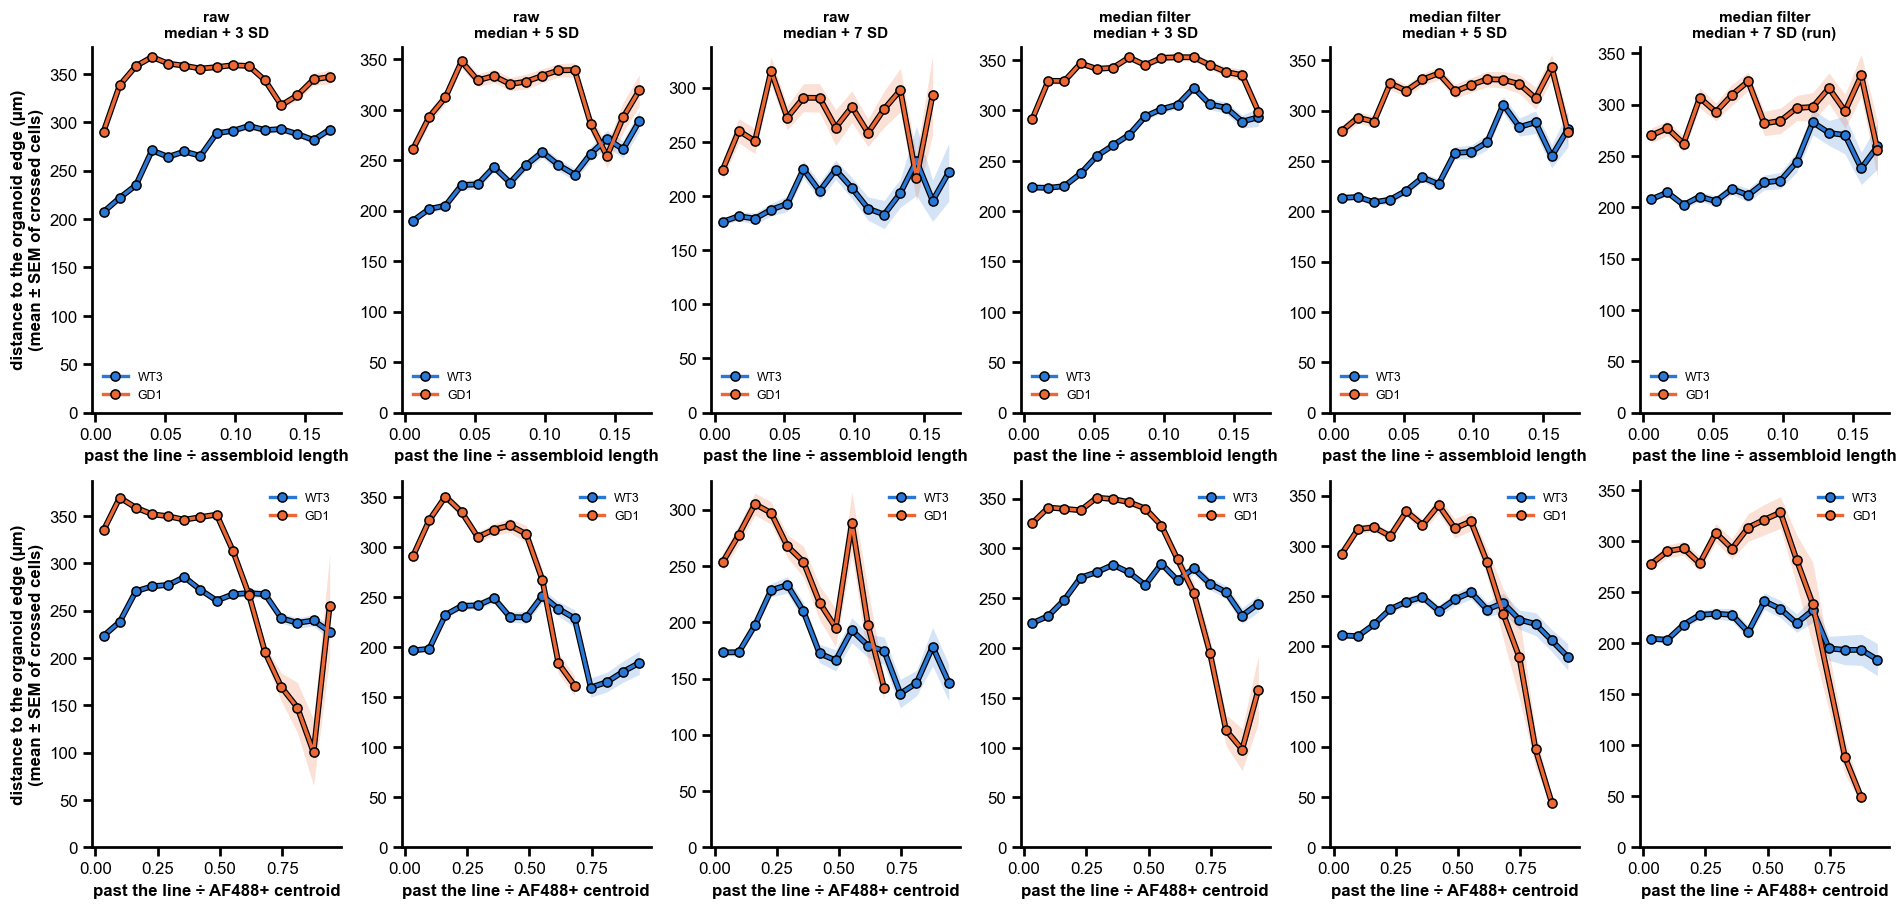

In [13]:
fig, axes = plt.subplots(len(SCALES), len(RULE_NAMES), figsize=(2.9 * len(RULE_NAMES), 4.2 * len(SCALES)),
                         squeeze=False)
for i, scale in enumerate(SCALES):
    column = f"past the line ÷ {scale}"
    top = float(np.nanpercentile(crossed_cells[column], 99))
    norm_bins = np.linspace(0, top, 16)
    norm_centres = (norm_bins[:-1] + norm_bins[1:]) / 2
    for j, rule in enumerate(RULE_NAMES):
        ax = axes[i, j]
        part = crossed_cells[(crossed_cells["rule"] == rule) & crossed_cells[column].notna()]
        for g in GENOTYPES:
            cg = part[part["Genotype"] == g]
            b = np.digitize(cg[column], norm_bins) - 1
            stat = cg.groupby(b)["to the edge (µm)"].agg(["mean", "sem", "size"]).reindex(range(len(norm_centres)))
            stat = stat[stat["size"] >= 10]
            x = norm_centres[stat.index]
            ax.fill_between(x, stat["mean"] - stat["sem"], stat["mean"] + stat["sem"], color=GENOTYPE_COLOURS[g],
                            alpha=0.2, lw=0)
            ax.plot(x, stat["mean"], color="black", lw=3.8, zorder=2)
            ax.plot(x, stat["mean"], color=GENOTYPE_COLOURS[g], lw=2.2, marker="o", ms=6, mec="black", mew=1,
                    zorder=3, label=g)
        if i == 0:
            ax.set_title(rule.replace(" · ", "\n"), fontsize=10)
        ax.set_xlabel(f"past the line ÷ {scale}")
        ax.set_ylim(bottom=0)
        ax.legend(fontsize=8)
        if j == 0:
            ax.set_ylabel("distance to the organoid edge (µm)\n(mean ± SEM of crossed cells)")
fig.tight_layout()
save(fig, "edge_vs_line_normalised")
plt.show()

## 8b. Where the AF488+ cells lie, relative to the size of the assembloid

Every AF488+ cell beside the line, at home (−) and past it (+), its distance to the line divided by its section's size; pooled per genotype as a **density histogram** (each genotype's area = 1), so the shape compares whatever the number of cells. One figure per way of normalising (assembloid length; AF488+ centroid distance), one panel per rule; below each, the same past the line only (the crossed side), with its own density, where the tail of the migrants is.

**No section cut short.** The cache holds cells within 650 µm of the line (`KEEP_UM`). The range shown, ±`limit`, is the largest that 95 % of sections reach within 650 µm (`limit` × size ≤ 650 µm); the 5 % largest sections, which would be cut short, are left out of these plots (the number is printed).

assembloid length: shown to ±0.24; 23 sections left out (too big to reach that within 650 µm, or no size)


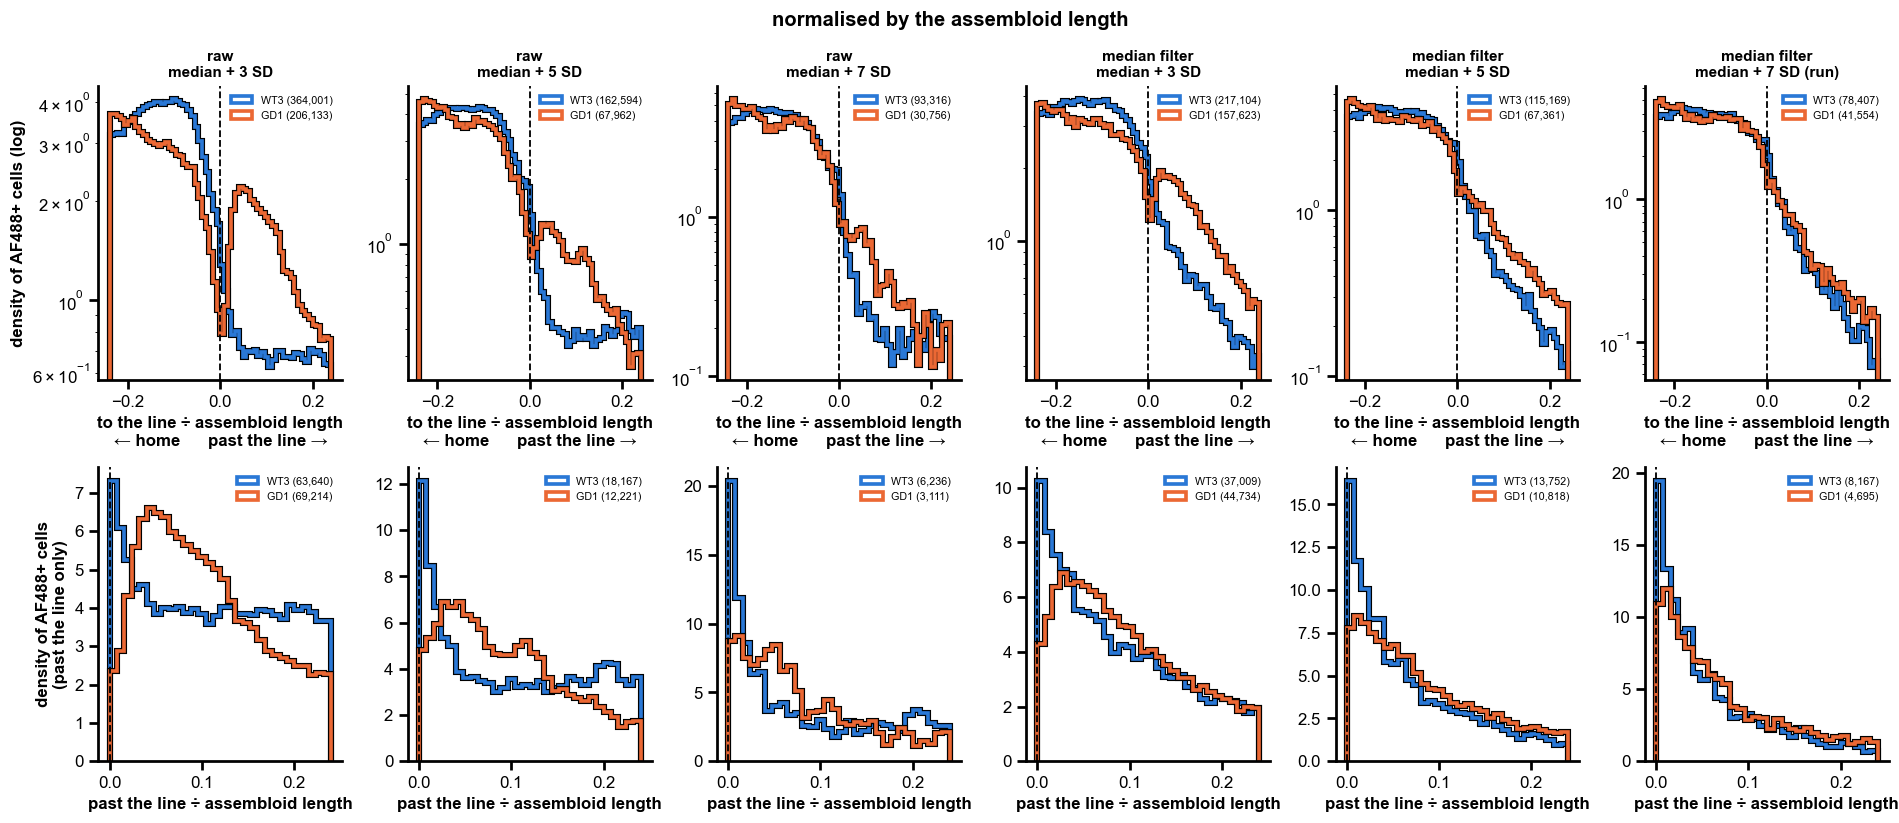

AF488+ centroid: shown to ±0.82; 30 sections left out (too big to reach that within 650 µm, or no size)


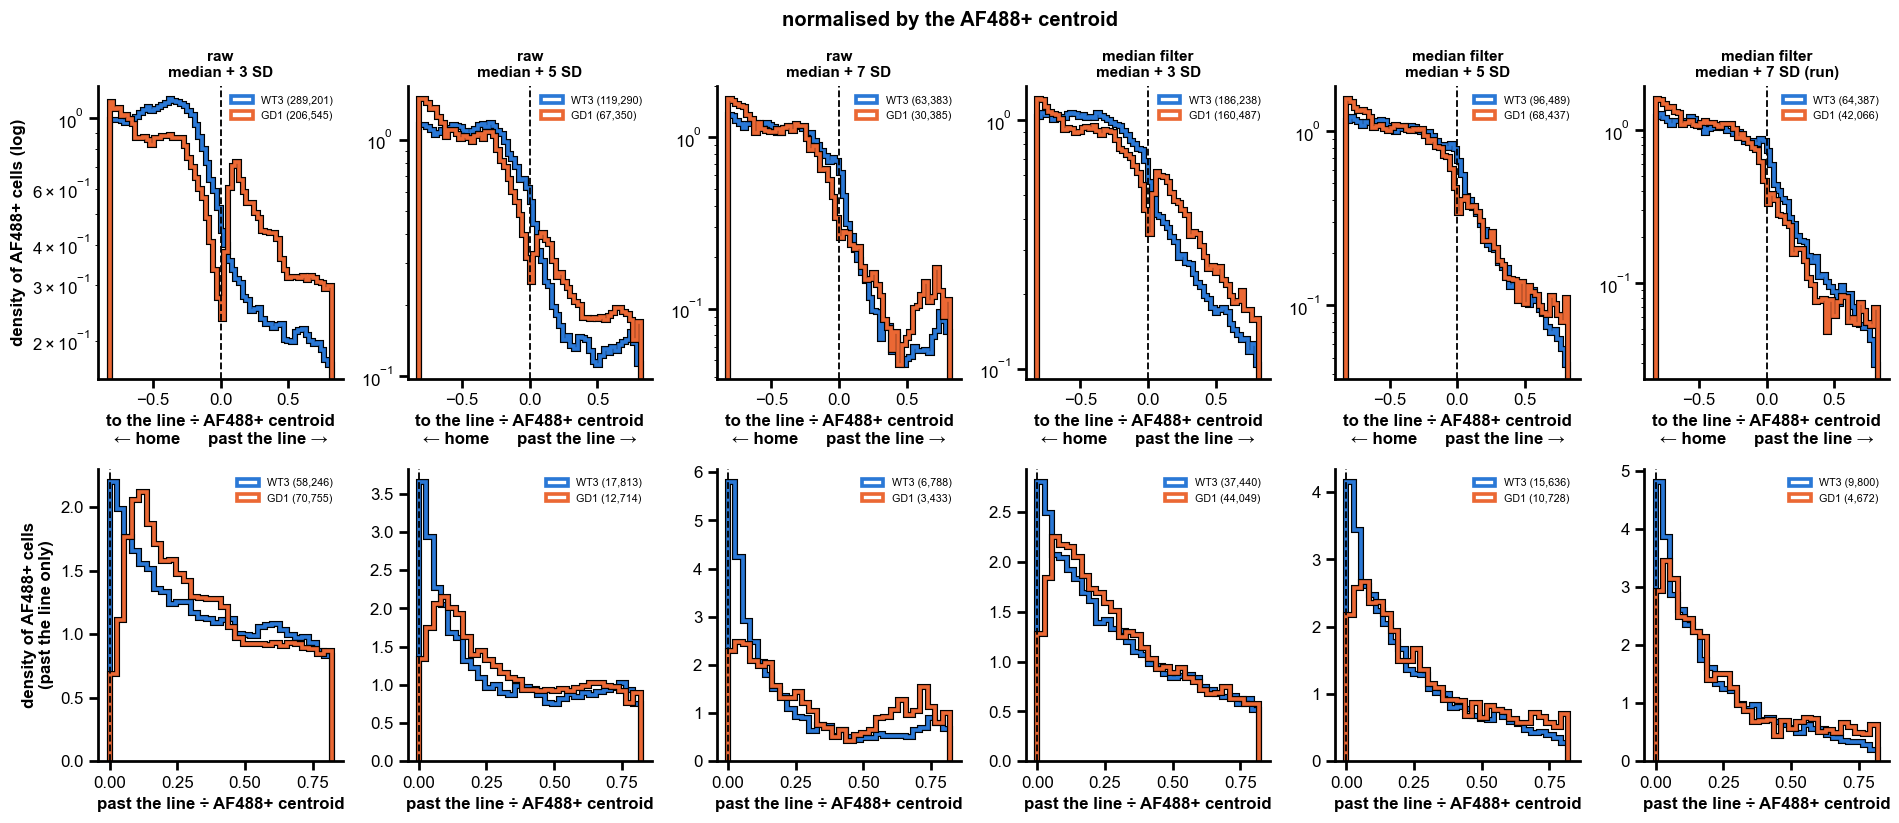

median position past the line of the crossed AF488+ cells, normalised:


assembloid length        AF488+ centroid       
Genotype                                          GD1    WT3             GD1    WT3
rule                                                                               
raw · median + 3 SD                             0.094  0.111           0.320  0.329
raw · median + 5 SD                             0.085  0.098           0.302  0.260
raw · median + 7 SD                             0.064  0.058           0.260  0.149
median filter · median + 3 SD                   0.084  0.074           0.268  0.255
median filter · median + 5 SD                   0.070  0.051           0.228  0.184
median filter · median + 7 SD (run)             0.055  0.040           0.185  0.159

In [14]:
medians = {}
for scale, size_column in SCALES.items():
    size = sections[size_column]
    limit = float(np.floor(KEEP_UM / size.quantile(0.95) / 0.02) * 0.02)
    used = sections.index[size.notna() & (size * limit <= KEEP_UM)]
    print(f"{scale}: shown to ±{limit:.2f}; {len(sections) - len(used)} sections left out "
          f"(too big to reach that within {KEEP_UM:.0f} µm, or no size)")
    bins = np.linspace(-limit, limit, 61)
    positions = []
    for name in used:
        c, s = cells[name], sections.loc[name]
        norm = c["away"].to_numpy() / s[size_column]
        beside = c["beside"].to_numpy(bool) & (np.abs(norm) <= limit)
        for rule in RULE_NAMES:
            positions.append(pd.DataFrame({"rule": rule, "Genotype": s["Genotype"],
                                           "position": norm[positive(c, rule) & beside]}))
    positions = pd.concat(positions, ignore_index=True)
    medians[scale] = positions[positions["position"] > 0].groupby(["rule", "Genotype"])["position"].median()

    fig, axes = plt.subplots(2, len(RULE_NAMES), figsize=(2.9 * len(RULE_NAMES), 7.6), squeeze=False)
    for j, rule in enumerate(RULE_NAMES):
        part = positions[positions["rule"] == rule]
        for row, (low, edges) in enumerate(((-limit, bins), (0.0, bins[bins >= -1e-9]))):
            ax = axes[row, j]
            for g in GENOTYPES:
                x = part.loc[(part["Genotype"] == g) & (part["position"] >= low), "position"]
                ax.hist(x, bins=edges, density=True, histtype="step", lw=4.0, color="black")
                ax.hist(x, bins=edges, density=True, histtype="step", lw=2.4, color=GENOTYPE_COLOURS[g],
                        label=f"{g} ({len(x):,})")
            ax.axvline(0, color="black", lw=1.2, ls="--")
            ax.legend(fontsize=7, loc="upper right")
            ax.set_xlabel(f"to the line ÷ {scale}\n← home      past the line →" if row == 0
                          else f"past the line ÷ {scale}")
            if row == 0:
                ax.set_title(rule.replace(" · ", "\n"), fontsize=10)
                ax.set_yscale("log")
            if j == 0:
                ax.set_ylabel("density of AF488+ cells" + (" (log)" if row == 0 else "\n(past the line only)"))
    fig.suptitle(f"normalised by the {scale}", fontweight="bold")
    fig.tight_layout()
    save(fig, f"positive_cells_density_{scale.replace(' ', '_').replace('+', 'pos')}")
    plt.show()

print("median position past the line of the crossed AF488+ cells, normalised:")
display(pd.concat(medians, axis=1).unstack().reindex(RULE_NAMES).round(3))

## 9. Same conclusions?

One cell per rule and outcome: the effect (fold WT3 / GD1, or difference WT3 − GD1) and the mixed model's stars. Blue = the figure is higher in WT3, orange = higher in GD1 — for the edge distance orange means WT3's crossed cells are *nearer* the edge; for the slope blue means WT3's crossed cells move away from the edge faster as they go further. Pale = not significant. Read a column down: if the colour and the stars hold, the rule does not change the conclusion.

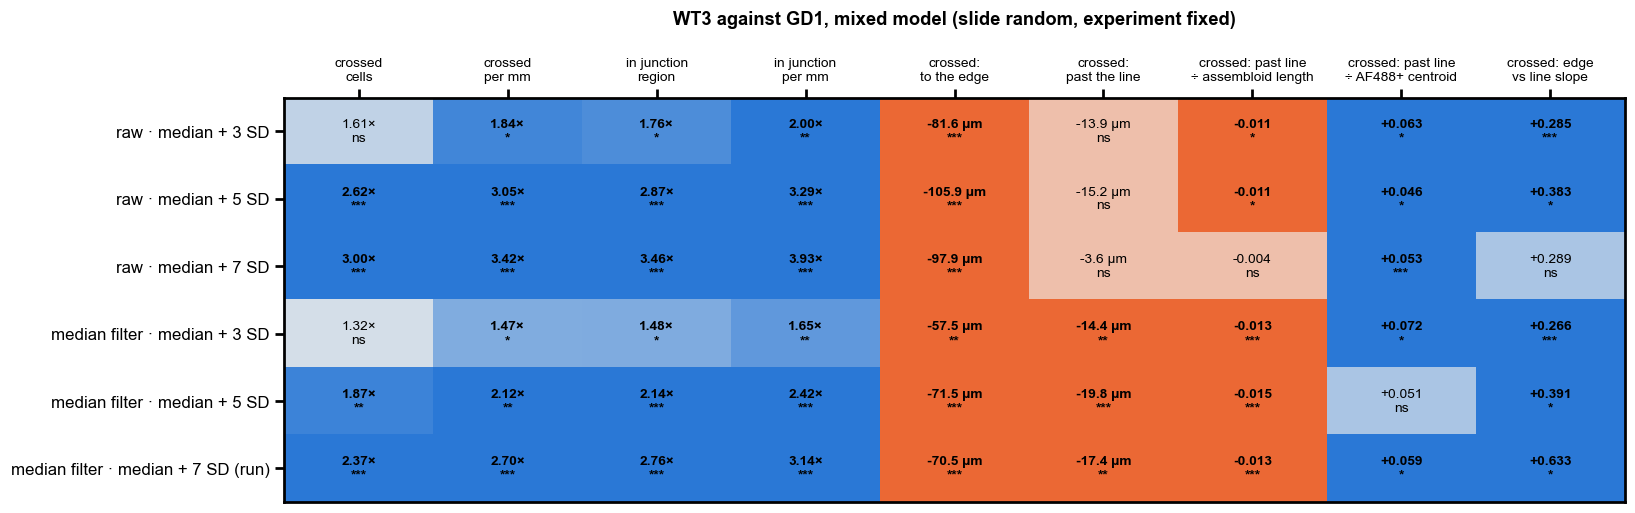

In [15]:
table = effects.pivot(index="rule", columns="outcome", values="effect").loc[RULE_NAMES, list(OUTCOMES)]
pvals = effects.pivot(index="rule", columns="outcome", values="p").loc[RULE_NAMES, list(OUTCOMES)]
signed = pd.DataFrame({o: (np.log2(table[o]) if OUTCOMES[o][0] == "fold" else np.sign(table[o]))
                       for o in OUTCOMES}).loc[RULE_NAMES]
shade = np.clip(signed.to_numpy(float), -1, 1) * np.where(pvals.to_numpy() < 0.05, 1.0, 0.35)
cmap = mpl.colors.LinearSegmentedColormap.from_list("g", [GENOTYPE_COLOURS["GD1"], "#f0efec", GENOTYPE_COLOURS["WT3"]])
fig, ax = plt.subplots(figsize=(15, 4.8))
ax.imshow(shade, cmap=cmap, vmin=-1, vmax=1, aspect="auto")
for i in range(len(RULE_NAMES)):
    for j, o in enumerate(OUTCOMES):
        v, p = table.iat[i, j], pvals.iat[i, j]
        if OUTCOMES[o][0] == "fold":
            text = f"{v:.2f}×"
        elif "µm" in o:
            text = f"{v:+.1f} µm"
        else:
            text = f"{v:+.3f}"
        ax.text(j, i, f"{text}\n{stars(p)}", ha="center", va="center", fontsize=9,
                fontweight="bold" if p < 0.05 else "normal")
HEADERS = {"crossed cells": "crossed\ncells", "crossed per mm": "crossed\nper mm", "cells in junction": "in junction\nregion",
           "in junction per mm": "in junction\nper mm", "crossed: mean distance to edge (µm)": "crossed:\nto the edge",
           "crossed: mean distance past line (µm)": "crossed:\npast the line",
           **{f"crossed: distance past line ÷ {scale}": f"crossed: past line\n÷ {scale}" for scale in SCALES},
           "crossed: edge vs line slope": "crossed: edge\nvs line slope"}
ax.set_xticks(range(len(OUTCOMES)), [HEADERS.get(o, o) for o in OUTCOMES], fontsize=9)
ax.set_yticks(range(len(RULE_NAMES)), RULE_NAMES)
ax.xaxis.tick_top()
for side in ax.spines.values():
    side.set_visible(True)
ax.set_title("WT3 against GD1, mixed model (slide random, experiment fixed)", pad=48)
fig.tight_layout()
save(fig, "conclusions")
plt.show()

## 10. What the rules call: example cells

Every cell near the junction (in the junction region, or within 300 µm of the line on either side) that at least one rule calls AF488+, sorted into four kinds:

| kind | what it suggests |
|---|---|
| **called by all six rules** | clearly labelled cells |
| **run's rule, not raw + 7 SD** | a labelled cell in dim surroundings: the raw bar (set by the whole region) is too high for it |
| **raw + 7 SD, not the run's rule** | bright because its surroundings are bright: the local median takes that away — likely false positives of the raw rules |
| **only the + 3 SD rules** | borderline cells and noise |

For each kind, `N_PER_GENOTYPE` cells of each genotype drawn at random (`SEED`), each from a different section: AF488 (maximum over the z-planes, as the analysis measures it) over 50 µm, the cell's nucleus outlined in white. Under each, one box per rule — **filled = called AF488+** — raw rules R3 R5 R7 (purple), median-filter rules M3 M5 M7 (blue; M7 is the run's). The brightness range is the same for every picture (`DISPLAY`), so a dim cell looks dim.

cells near the junction called by at least one rule, by kind:


Genotype,WT3,GD1
called by all six rules,37033,9681
"run's rule, not raw + 7 SD",21561,15842
"raw + 7 SD, not the run's rule",25598,8180
only the + 3 SD rules,173576,127428


median local background (raw − filtered mean) of each kind:


called by all six rules           532.0
run's rule, not raw + 7 SD        398.0
raw + 7 SD, not the run's rule    752.0
only the + 3 SD rules             498.0
Name: local background, dtype: float32

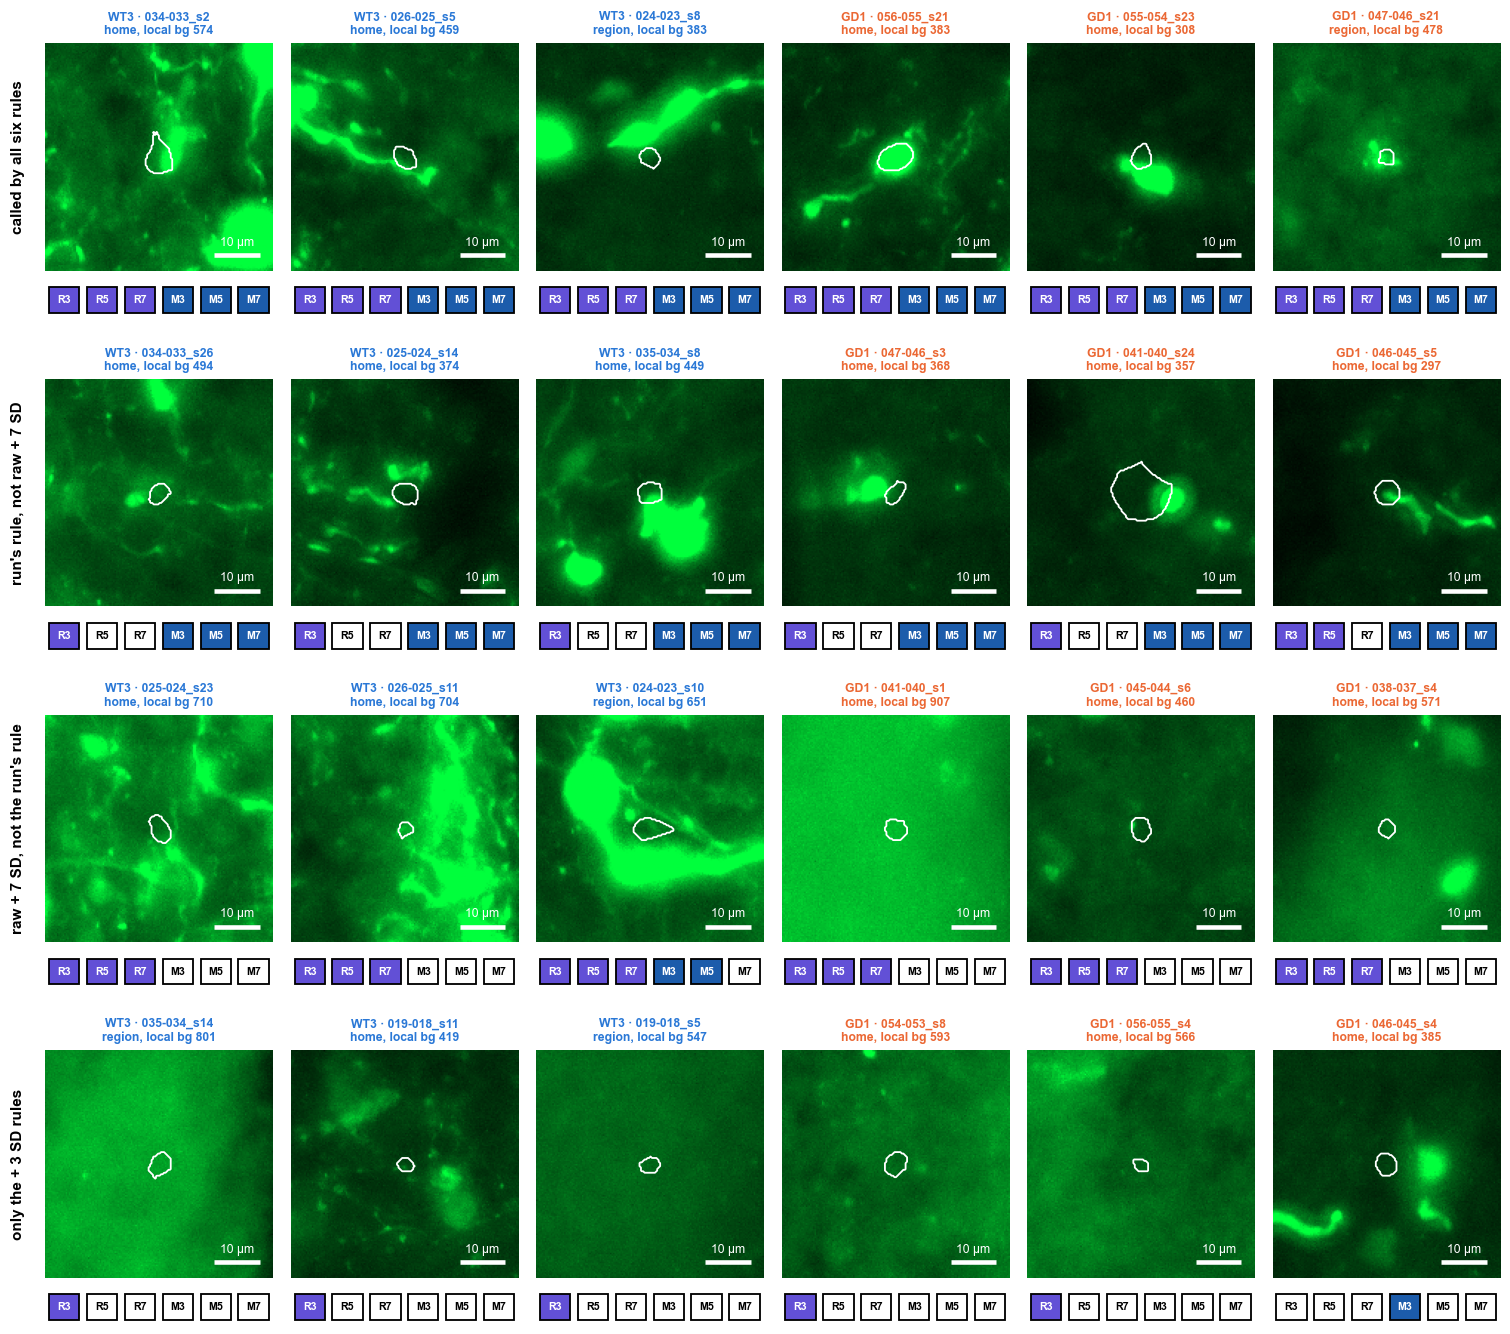

In [16]:
import logging
import sys

logging.getLogger("tifffile").setLevel(logging.ERROR)   # OME headers with odd characters: harmless

ROOT = Path.cwd().resolve()
while not (ROOT / "microscopy_viewer").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import tifffile  # noqa: E402

from microscopy_viewer import junction_analysis as ja  # noqa: E402
from microscopy_viewer import loaders  # noqa: E402

SEED = 1
N_PER_GENOTYPE = 3
CROP_UM = 50.0                    # side of an example cell's picture
REGION_UM = 160.0                 # side of a bright-background picture
DISPLAY = (150.0, 1200.0)         # AF488 shown from black to full green (raw values)
SHORT = dict(zip(RULE_NAMES, ["R3", "R5", "R7", "M3", "M5", "M7"]))
RULE_COLOURS = {"R": "#6250d6", "M": "#1c5cab"}
GREEN = mpl.colors.LinearSegmentedColormap.from_list("green", ["black", "#00ff3c"])

# Every cell near the junction that some rule calls, with each rule's call.
candidates = []
for name, s in sections.iterrows():
    c = cells[name]
    calls = np.column_stack([positive(c, rule) for rule in RULE_NAMES])
    near = c["region"].to_numpy(bool) | (c["beside"].to_numpy(bool) & (c["away"].abs().to_numpy() <= NEAR_UM))
    keep = calls.any(axis=1) & near
    frame = pd.DataFrame(calls[keep], columns=list(SHORT.values()))
    frame["name"], frame["Genotype"] = name, s["Genotype"]
    for column in ("label", "y", "x", "away", "region"):
        frame[column] = c.loc[keep, column].to_numpy()
    frame["local background"] = (c.loc[keep, RAW] - c.loc[keep, FILTERED]).to_numpy()
    candidates.append(frame)
candidates = pd.concat(candidates, ignore_index=True)

KINDS = {
    "called by all six rules": lambda d: d[list(SHORT.values())].all(axis=1),
    "run's rule, not raw + 7 SD": lambda d: d["M7"] & ~d["R7"],
    "raw + 7 SD, not the run's rule": lambda d: d["R7"] & ~d["M7"],
    "only the + 3 SD rules": lambda d: (d["R3"] | d["M3"]) & ~d[["R5", "R7", "M5", "M7"]].any(axis=1),
}
print("cells near the junction called by at least one rule, by kind:")
display(pd.DataFrame({kind: candidates[test(candidates)].groupby("Genotype").size() for kind, test in KINDS.items()}).T
        .reindex(columns=GENOTYPES).fillna(0).astype(int))
print("median local background (raw − filtered mean) of each kind:")
display(pd.Series({kind: candidates.loc[test(candidates), "local background"].median() for kind, test in KINDS.items()})
        .round(0).rename("local background"))


def pick(frame, n, rng):
    """n cells of *frame*, at random, each from a different section."""
    order = frame.sample(frac=1.0, random_state=int(rng.integers(1 << 31)))
    return order.drop_duplicates("name").head(n)


rng = np.random.default_rng(SEED)
chosen = []
for kind, test in KINDS.items():
    for g in GENOTYPES:
        part = candidates[test(candidates) & (candidates["Genotype"] == g)]
        chosen.append(pick(part, N_PER_GENOTYPE, rng).assign(kind=kind))
chosen = pd.concat(chosen, ignore_index=True)


def section_info(name):
    return json.loads((RUN / "cells" / f"{name}.json").read_text(encoding="utf-8"))


def read_window(name, centre_um, side_um, channels=("AF488",), filtered=False):
    """The section's channels (maximum over z, as the analysis) and its nuclei over a square round *centre_um*."""
    info = section_info(name)
    voxel = float(info["voxel_yx"][0])
    height, width = info["shape_yx"]
    half = int(round(side_um / 2 / voxel))
    cy, cx = int(round(centre_um[0] / voxel)), int(round(centre_um[1] / voxel))
    window = (slice(max(cy - half, 0), min(cy + half, height)), slice(max(cx - half, 0), min(cx + half, width)))
    path = Path(info["file"])
    specs = loaders.load_path(path)
    try:
        names = [str(spec.channel_name or spec.name) for spec in specs]
        out = {ch: ja._plane(specs[names.index(ch)], window).astype(np.float32) for ch in channels}
        if filtered:
            for ch in channels:
                out[f"{ch} filtered"] = ja.filtered_plane(specs[names.index(ch)], voxel)[window]
    finally:
        loaders.release(path)
    out["nuclei"] = tifffile.imread(RUN / info["nuclei_file"])[window]
    out["origin_um"] = (window[0].start * voxel, window[1].start * voxel)
    out["voxel"] = voxel
    return out


def scale_bar(ax, image, voxel, um):
    h, w = image.shape
    length = um / voxel
    ax.plot([w - length - 0.06 * w, w - 0.06 * w], [h - 0.07 * h] * 2, color="white", lw=3, solid_capstyle="butt")
    ax.text(w - length / 2 - 0.06 * w, h - 0.1 * h, f"{um:g} µm", color="white", ha="center", va="bottom", fontsize=8)


def call_strip(ax, row):
    """One box per rule under a picture: filled when the rule calls the cell AF488+."""
    strip = ax.inset_axes([0.0, -0.2, 1.0, 0.14])
    for k, short in enumerate(SHORT.values()):
        colour = RULE_COLOURS[short[0]]
        strip.add_patch(mpl.patches.Rectangle((k + 0.1, 0.1), 0.8, 0.8, facecolor=colour if row[short] else "white",
                                              edgecolor="black", linewidth=1.2))
        strip.text(k + 0.5, 0.5, short, ha="center", va="center", fontsize=7, fontweight="bold",
                   color="white" if row[short] else "black")
    strip.set_xlim(0, 6)
    strip.set_ylim(0, 1)
    strip.axis("off")


fig, axes = plt.subplots(len(KINDS), 2 * N_PER_GENOTYPE, figsize=(2.3 * 2 * N_PER_GENOTYPE, 3.0 * len(KINDS)))
for i, kind in enumerate(KINDS):
    rows = chosen[chosen["kind"] == kind].reset_index(drop=True)
    for j in range(2 * N_PER_GENOTYPE):
        ax = axes[i, j]
        ax.set_xticks([]); ax.set_yticks([])
        for side in ax.spines.values():
            side.set_visible(False)
        if j >= len(rows):
            ax.axis("off")
            continue
        row = rows.iloc[j]
        crop = read_window(row["name"], (row["y"], row["x"]), CROP_UM)
        ax.imshow(np.clip((crop["AF488"] - DISPLAY[0]) / (DISPLAY[1] - DISPLAY[0]), 0, 1), cmap=GREEN, vmin=0, vmax=1)
        ax.contour(crop["nuclei"] == row["label"], levels=[0.5], colors="white", linewidths=1.2)
        scale_bar(ax, crop["AF488"], crop["voxel"], 10)
        where = "region" if row["region"] else ("crossed" if row["away"] > 0 else "home")
        ax.set_title(f"{row['Genotype']} · {row['name'].split('Asssembloid_')[-1]}\n{where}, "
                     f"local bg {row['local background']:.0f}", fontsize=8, color=GENOTYPE_COLOURS[row["Genotype"]],
                     fontweight="bold")
        call_strip(ax, row)
    axes[i, 0].text(-0.12, 0.5, kind, transform=axes[i, 0].transAxes, rotation=90, ha="center", va="center",
                    fontsize=10, fontweight="bold")
fig.tight_layout(h_pad=3.5)
save(fig, "example_cells")
plt.show()

## 11. Bright background: where the raw rules call cells the run's rule does not

Cells called by raw + 7 SD but by **none** of the median-filter rules — not even + 3 SD: nothing stands out of their surroundings. Each picture is centred where such cells crowd together with few cells the run's rule calls: for every one of them, the number of its kind within `REGION_UM` / 2 less `RUN_WEIGHT` × the run's calls there; the best place of each section, and the `N_PER_GENOTYPE_REGIONS` best sections of each genotype. "local bg" is the local median under the centre cell (raw − filtered mean). Each over 160 µm: left, AF488 as measured; right, AF488 less its local median (45 µm) — what the run's rule compares. Each picture is scaled to its own range (1st to 99.5th percentile), so the haze is visible. Rings: **magenta** = called by raw + 5 SD, **yellow** = called by the run's rule (median filter + 7 SD). Magenta rings over an evenly bright patch with no yellow are a bright background read as cells.

cells called by raw + 7 SD and by no median-filter rule: WT3 16,507, GD1 5,773


,name,Genotype,raw-only nearby,run's calls nearby,local background
81,2025_09_26_Asssembloid_028-027_s1,WT3,337,21,635.0
9,2025_09_26_Asssembloid_019-018_s24,WT3,273,9,889.0
178,2025_09_26_Asssembloid_054-053_s4,GD1,199,0,994.0
159,2025_09_26_Asssembloid_045-044_s14,GD1,178,1,624.0


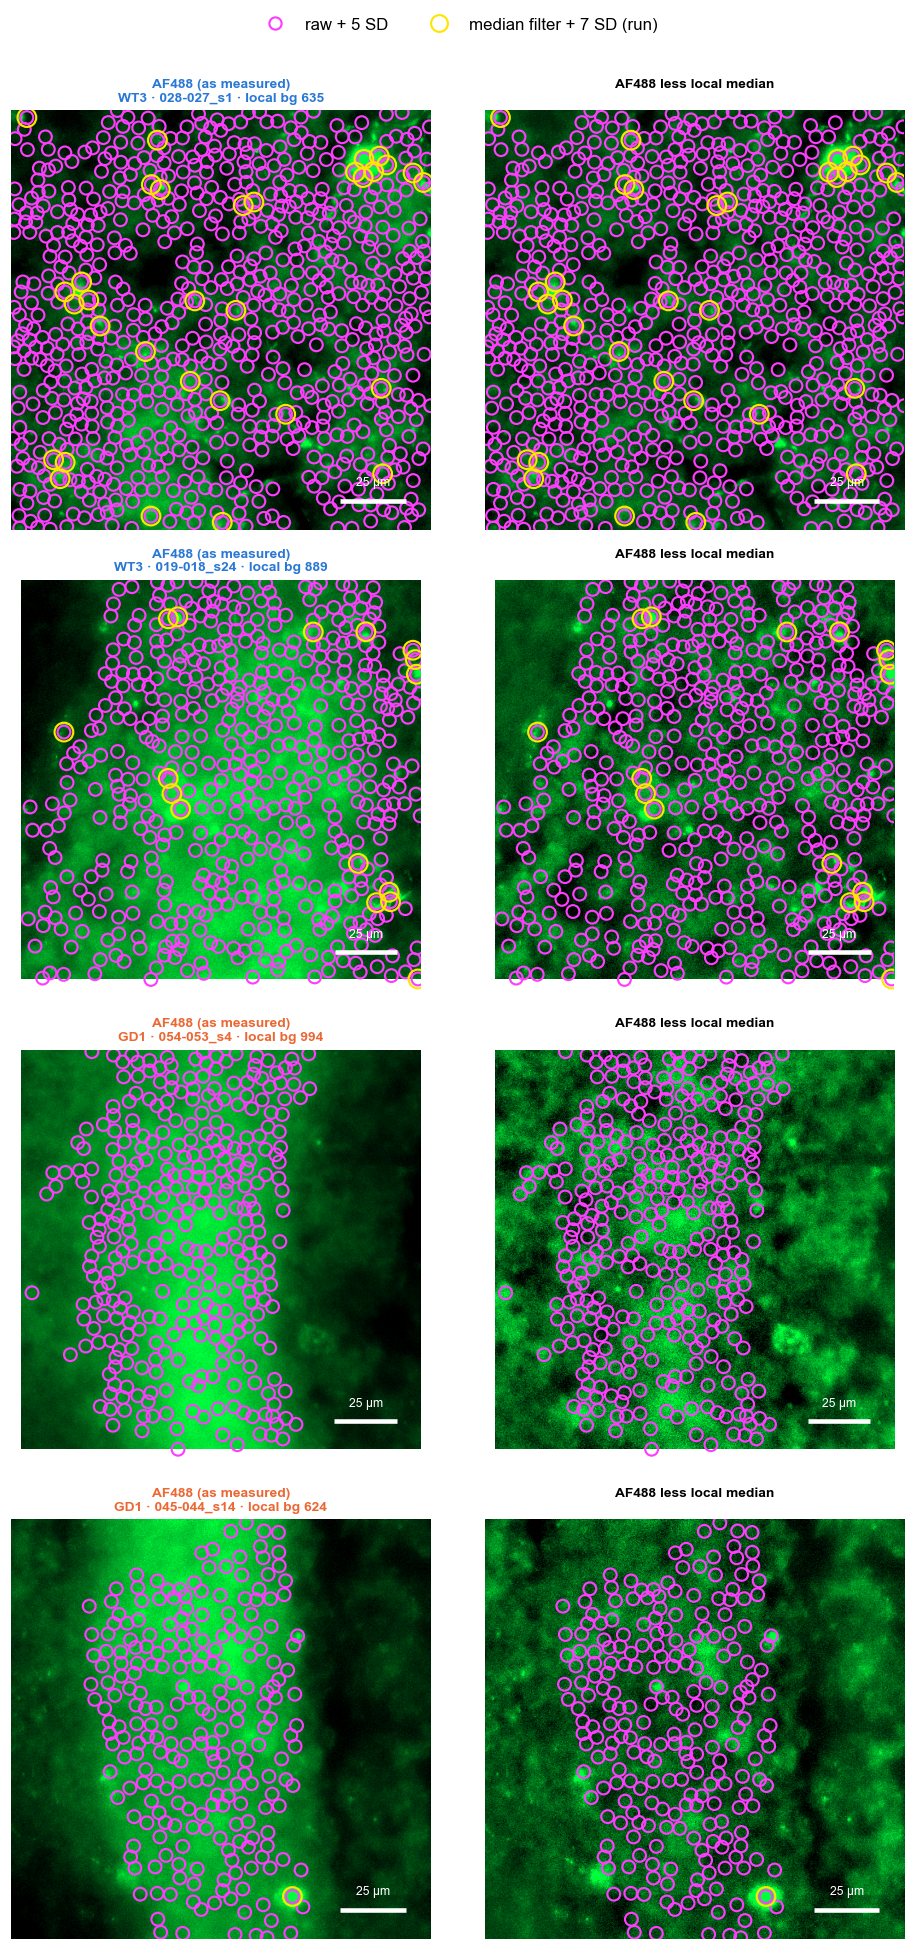

In [17]:
N_PER_GENOTYPE_REGIONS = 2
raw_only = candidates[candidates["R7"] & ~candidates[["M3", "M5", "M7"]].any(axis=1)]
print(f"cells called by raw + 7 SD and by no median-filter rule: "
      + ", ".join(f"{g} {int((raw_only['Genotype'] == g).sum()):,}" for g in GENOTYPES))
RUN_WEIGHT = 3.0
from scipy.spatial import cKDTree  # noqa: E402

best = []
for name, part in raw_only.groupby("name"):
    if len(part) < 5:
        continue
    run_calls = candidates[(candidates["name"] == name) & candidates["M7"]]
    points = part[["y", "x"]].to_numpy()
    crowd = np.array([len(n) for n in cKDTree(points).query_ball_point(points, REGION_UM / 2)])
    called = (np.array([len(n) for n in cKDTree(run_calls[["y", "x"]].to_numpy()).query_ball_point(points, REGION_UM / 2)])
              if len(run_calls) else np.zeros(len(part)))
    score = crowd - RUN_WEIGHT * called
    k = int(np.argmax(score))
    best.append(part.iloc[k].to_dict() | {"score": score[k], "raw-only nearby": crowd[k], "run's calls nearby": called[k]})
best = pd.DataFrame(best)
regions = pd.concat([best[best["Genotype"] == g].nlargest(N_PER_GENOTYPE_REGIONS, "score") for g in GENOTYPES])
display(regions[["name", "Genotype", "raw-only nearby", "run's calls nearby", "local background"]].round(0))
fig, axes = plt.subplots(len(regions), 2, figsize=(9, 4.4 * len(regions)), squeeze=False)
for i, (_, row) in enumerate(regions.iterrows()):
    crop = read_window(row["name"], (row["y"], row["x"]), REGION_UM, filtered=True)
    oy, ox = crop["origin_um"]
    here = candidates[(candidates["name"] == row["name"])]
    in_view = (here["y"] - oy).between(0, REGION_UM) & (here["x"] - ox).between(0, REGION_UM)
    here = here[in_view]
    for k, (image, title) in enumerate(((crop["AF488"], "AF488 (as measured)"),
                                        (crop["AF488 filtered"], "AF488 less local median"))):
        ax = axes[i, k]
        limits = np.percentile(image, [1, 99.5])
        ax.imshow(np.clip((image - limits[0]) / max(limits[1] - limits[0], 1), 0, 1), cmap=GREEN, vmin=0, vmax=1)
        for column, colour, size in (("R5", "#ff3cff", 70), ("M7", "#ffe600", 150)):
            pts = here[here[column]]
            ax.scatter((pts["x"] - ox) / crop["voxel"], (pts["y"] - oy) / crop["voxel"], s=size, facecolors="none",
                       edgecolors=colour, linewidths=1.4)
        ax.set_xticks([]); ax.set_yticks([])
        for side in ax.spines.values():
            side.set_visible(False)
        scale_bar(ax, image, crop["voxel"], 25)
        ax.set_title(f"{title}" + (f"\n{row['Genotype']} · {row['name'].split('Asssembloid_')[-1]} · "
                                   f"local bg {row['local background']:.0f}" if k == 0 else "\n"),
                     fontsize=9, color="black" if k else GENOTYPE_COLOURS[row["Genotype"]], fontweight="bold")
handles = [mpl.lines.Line2D([], [], marker="o", ls="", mfc="none", mec="#ff3cff", mew=1.4, ms=8, label="raw + 5 SD"),
           mpl.lines.Line2D([], [], marker="o", ls="", mfc="none", mec="#ffe600", mew=1.4, ms=11,
                            label="median filter + 7 SD (run)")]
fig.legend(handles=handles, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.01))
fig.tight_layout(rect=(0, 0, 1, 0.98))
save(fig, "bright_background")
plt.show()

## What it showed (29 October 2026: 614 sections, 36 slides — 265 WT3, 349 GD1)

**Same conclusions under all six rules; only the size of the difference changes.**

- **Crossed AF488+ cells: more in WT3 under every rule.**
  - Per mm of junction: 1.5–3.4×, significant under all six (p 0.001–0.02).
  - Per section: 1.3–3.0×, significant except under the two lenient rules. Raw + 3 SD gives 1.6× (p 0.095), median filter + 3 SD 1.3× (p 0.13).
  - Per mm is the fairer measure: sections differ in how much junction they cut.
- **AF488+ cells in the junction region: more in WT3 under every rule.** 1.5–3.5× per section, 1.6–3.9× per mm, all p < 0.05.
- **The stricter the rule, the bigger the difference** (median filter: 1.5× → 2.1× → 2.7× per mm at 3, 5, 7 SD). A lenient bar also calls background cells, about equally in both genotypes, which dilutes the fold. Raw + 3 SD calls ~100 crossed cells per section in both genotypes, against ~10–20 with the run's rule. Those are mostly not labelled cells.
- **Crossed cells lie nearer the organoid edge in WT3**: 58–106 µm nearer on average under every rule (p ≤ 0.008). Per section the mean distance is about 210–245 µm in WT3 against 295–330 µm in GD1.
- **Edge against distance past the line.** WT3's crossed cells hug the surface just past the line (~200–220 µm from the edge) and lie deeper the further they went: the slope is +0.2–0.3 µm per µm. GD1's sit deeper from the start (~300–350 µm) and the slope is flat (−0.1 to 0). The difference is significant under five rules. Under raw + 7 SD it is not (p 0.52): there only 180 WT3 and 121 GD1 sections have 3 or more crossed cells.

**The pictures (sections 10–11).**
- **Called by all six rules**: bright cell bodies with processes, the nucleus inside or beside the stain. These are labelled cells.
- **Run's rule but not raw + 7 SD**: real labelled cells in dimmer tissue. The raw bar, set by the whole region, is too high for them.
- **Raw + 7 SD but not the run's rule**: a mix.
  - In WT3, cells inside densely labelled tissue that the local median takes away with the background.
  - In GD1, evenly bright haze with no cell in it: false positives of the raw rules.
- **Only the + 3 SD rules**: mostly no visible label at all. That is the noise that dilutes the lenient rules' genotype difference.
- **Bright background**: diffuse bright bands where raw + 5 SD calls hundreds of "cells" within 80 µm and the run's rule 0–21, in both genotypes. Cells called by raw + 7 SD and by no median-filter rule number 16,500 in WT3 and 5,800 in GD1 near the junction.
- Taking the local median away is what removes these, which is why the run's rule uses the median-filtered mean.

**How far past the line, relative to the size of the assembloid (sections 7b, 8b).**
- **The sizes differ by genotype.** WT3 assembloids are a little longer across the line (median 2.03 mm against 1.87 mm). WT3's AF488+ cells sit much nearer the line (their centre 468 µm from it, against 633 µm in GD1): WT3's labelled cells crowd towards the junction.
- **In µm, GD1's crossed cells go further**: 14–20 µm under the median-filter rules (p ≤ 0.005).
- **Divided by the assembloid length, the same**: GD1's go 0.011–0.015 assembloid lengths further, significant under five of six rules (p < 0.001 with the run's rule).
- **Divided by the AF488+ centroid's distance, it flips**: WT3's go further, by 0.05–0.07 (significant under five of six). That is the denominator, not the cells. WT3's labelled centre is nearer the line, so the same distance past the line is a bigger fraction of it.
- **Normalised positions (8b).** The density shapes are close under the strict rules whichever way they are normalised. WT3 has a peak right at the line (cells just across, along the surface, as in section 8). Pooled over cells, the median crossed position is lower in WT3 under every strict rule (run's rule: 0.040 against 0.055 assembloid lengths, 0.159 against 0.185 centroid distances). The section-level model on the centroid scale says the opposite, so read that scale with care.
- **Take-away.** GD1's crossed cells are not closer to the line. In µm and per assembloid length they reach slightly further. WT3's sit more at the line and along the surface. The AF488+ centroid is not a neutral yardstick here: it moves with where the labelled cells are, which differs by genotype.

**Read with care.**
- More crossed cells in WT3 goes with more AF488+ cells near the line on WT3's own side (`03_cells_run`, sections 6 and 9). The share of labelled cells that crossed is the same in both genotypes, so these counts say "more labelled cells", not "more migration".
- The edge-distance result is the one that differs in kind: WT3's migrants travel along the surface, GD1's do not.
- "Edge" is the nearest tissue edge in a 2D section, so it includes cut faces and tears.